In [5]:
import os

In [6]:
BASE_DIR = "thesis_artifacts/preprocessing_run_01"
GRU_DIR = "thesis_artifacts/gru_run_01"
RF_DIR = "thesis_artifacts/rf_run_01"

In [7]:
os.listdir(BASE_DIR)
os.listdir(GRU_DIR)

['gru_predictions.npz', 'gru_test_predictions.csv', 'gru_val_predictions.csv']

In [8]:
%pip install numpy pandas scikit-learn

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'd:\Pycode\Test\compile_pipeline\.venv\Scripts\python.exe -m pip install --upgrade pip' command.


In [9]:
import numpy as np
import pandas as pd

In [10]:
import os

In [11]:
# =====================================================
# LOAD PREPROCESSED DATA + GRU OUTPUTS FROM GOOGLE DRIVE
# =====================================================


# ---- Load preprocessed tensors
data = np.load(os.path.join(BASE_DIR, "preprocessed_data_gru_run.npz"), allow_pickle=True)

X_tab_train = data["X_tab_train"]
X_tab_val   = data["X_tab_val"]
X_tab_test  = data["X_tab_test"]

y_train = data["y_train"]
y_val   = data["y_val"]
y_test  = data["y_test"]

label_mapping = data["label_mapping"].item()
num_classes   = int(data["num_classes"])

print("✅ Loaded preprocessed data")

# ---- Load GRU predictions
gru_out = np.load(os.path.join(GRU_DIR, "gru_predictions.npz"), allow_pickle=True)

gru_val_probs  = gru_out["val_probs"]
gru_test_probs = gru_out["test_probs"]

gru_val_preds  = gru_out["val_preds"]
gru_test_preds = gru_out["test_preds"]

class_names = gru_out["class_names"].tolist()

print("✅ Loaded GRU predictions")


✅ Loaded preprocessed data
✅ Loaded GRU predictions


In [44]:
# =====================================================
# CLASS DISTRIBUTION IN TRAINING SET
# =====================================================
import pandas as pd
import numpy as np

print("="*60)
print("📊 CLASS DISTRIBUTION (TRAINING SET)")
print("="*60)

# Convert to Series if needed
y_train_series = pd.Series(y_train) if not isinstance(y_train, pd.Series) else y_train

# Count per class
class_counts = y_train_series.value_counts().sort_index()

# Build distribution table
dist_df = pd.DataFrame({
    "Class": [class_names[i] if i < len(class_names) else f"Class {i}" for i in class_counts.index],
    "Count": class_counts.values,
    "Percentage": (class_counts.values / len(y_train) * 100).round(2)
})

print(f"\nTotal training samples: {len(y_train):,}")
print(f"Number of classes: {num_classes}\n")

display(dist_df.style.format({"Count": "{:,}", "Percentage": "{:.2f}%"}))

# Quick summary
print(f"\nMin class size: {class_counts.min():,} ({dist_df.loc[class_counts.argmin(), 'Class']})")
print(f"Max class size: {class_counts.max():,} ({dist_df.loc[class_counts.argmax(), 'Class']})")
print(f"Imbalance ratio (max/min): {class_counts.max() / class_counts.min():.2f}x")

📊 CLASS DISTRIBUTION (TRAINING SET)

Total training samples: 7,619,207
Number of classes: 20



,Class,Count,Percentage
0,benign,"3,201,089",42.01%
1,ddos,"2,766,337",36.31%
2,scanning,"480,995",6.31%
3,reconnaissance,"335,111",4.40%
4,xss,"312,195",4.10%
5,injection,"87,158",1.14%
6,dos,"227,234",2.98%
7,bot,"18,199",0.24%
8,brute force,"15,770",0.21%
9,infilteration,"14,799",0.19%



Min class size: 202 (ransomware)
Max class size: 3,201,089 (benign)
Imbalance ratio (max/min): 15846.98x


In [12]:
%pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'd:\Pycode\Test\compile_pipeline\.venv\Scripts\python.exe -m pip install --upgrade pip' command.


In [13]:
# # -----------------------------------------------------
# # GRU training history plots (loss/accuracy)
# # -----------------------------------------------------
# import matplotlib.pyplot as plt

# print("GRU artifact keys:", gru_out.files)

# # Helper to fetch the first available key from a list of candidates

# def pick_key(candidates):
#     for key in candidates:
#         if key in gru_out.files:
#             return key
#     return None

# loss_key = pick_key(["history_loss", "loss", "train_loss"])
# val_loss_key = pick_key(["history_val_loss", "val_loss", "validation_loss"])
# acc_key = pick_key(["history_accuracy", "accuracy", "acc", "train_accuracy"])
# val_acc_key = pick_key(["history_val_accuracy", "val_accuracy", "val_acc"])

# required = {
#     "train loss": loss_key,
#     "val loss": val_loss_key,
#     "train acc": acc_key,
#     "val acc": val_acc_key,
# }
# missing = [name for name, key in required.items() if key is None]
# if missing:
#     raise ValueError(
#         f"Missing history keys for: {missing}. "
#         f"Available keys: {list(gru_out.files)}"
#     )

# train_loss = gru_out[loss_key]
# val_loss = gru_out[val_loss_key]
# train_acc = gru_out[acc_key]
# val_acc = gru_out[val_acc_key]

# n_epochs = min(len(train_loss), len(val_loss), len(train_acc), len(val_acc))
# epochs = np.arange(1, n_epochs + 1)

# fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# axes[0].plot(epochs, train_loss[:n_epochs], label="train")
# axes[0].plot(epochs, val_loss[:n_epochs], label="val")
# axes[0].set_title("GRU Loss")
# axes[0].set_xlabel("Epoch")
# axes[0].set_ylabel("Loss")
# axes[0].legend()
# axes[0].grid(True, alpha=0.3)

# axes[1].plot(epochs, train_acc[:n_epochs], label="train")
# axes[1].plot(epochs, val_acc[:n_epochs], label="val")
# axes[1].set_title("GRU Accuracy")
# axes[1].set_xlabel("Epoch")
# axes[1].set_ylabel("Accuracy")
# axes[1].legend()
# axes[1].grid(True, alpha=0.3)

# fig.suptitle("GRU Training History", y=1.05)
# plt.tight_layout()
# plt.show()


In [14]:
# =====================================================
# LOAD RANDOM FOREST ARTIFACTS (MODEL + PREDICTIONS)
# =====================================================

import joblib

rf_bundle = joblib.load(os.path.join(RF_DIR, "rf_model_bundle.joblib"))

rf_out = np.load(os.path.join(RF_DIR, "rf_predictions.npz"), allow_pickle=True)

rf_val_probs  = rf_out["val_probs"]
rf_test_probs = rf_out["test_probs"]

rf_val_preds  = rf_out["val_preds"]
rf_test_preds = rf_out["test_preds"]

if "class_names" in rf_out.files:
    rf_class_names = rf_out["class_names"].tolist()
elif "class_names" in globals():
    rf_class_names = class_names
else:
    rf_class_names = None

print("✅ Loaded RF model bundle + predictions")
print(f"rf_predictions keys: {rf_out.files}")


d:\Pycode\Test\compile_pipeline\.venv\lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
d:\Pycode\Test\compile_pipeline\.venv\lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator RandomForestClassifier from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


✅ Loaded RF model bundle + predictions
rf_predictions keys: ['val_probs', 'test_probs', 'val_preds', 'test_preds', 'y_val', 'y_test', 'class_names']


In [15]:
# =====================================================
# STEP 5: Train KNN Model (STRATIFIED SUBSET)
# =====================================================
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

print("\n" + "="*60)
print("🎯 TRAINING KNN MODEL (STRATIFIED SUBSET)")
print("="*60)

# -----------------------------------------------------
# 1) Define subset size (adjustable)
# -----------------------------------------------------
SUBSET_RATIO = 0.2   # 20% of training data (reasonable for KNN)
RANDOM_STATE = 42

sss = StratifiedShuffleSplit(
    n_splits=1,
    train_size=SUBSET_RATIO,
    random_state=RANDOM_STATE
)

for subset_idx, _ in sss.split(X_tab_train, y_train):
    X_knn_train = X_tab_train[subset_idx]
    y_knn_train = y_train.iloc[subset_idx] if hasattr(y_train, "iloc") else y_train[subset_idx]

print(f"✅ KNN trained on {len(X_knn_train):,} samples "
      f"({SUBSET_RATIO*100:.0f}% of training set)")

# -----------------------------------------------------
# 2) Train KNN
# -----------------------------------------------------
knn = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance",
    metric="minkowski",
    n_jobs=-1
)

print("🚀 Training KNN...")
knn.fit(X_knn_train, y_knn_train)




🎯 TRAINING KNN MODEL (STRATIFIED SUBSET)
✅ KNN trained on 1,523,841 samples (20% of training set)
🚀 Training KNN...


,n_neighbors,5
,weights,'distance'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,-1


In [16]:
# =====================================================
# STRATIFIED VALIDATION SUBSET FOR KNN
# =====================================================
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

# -----------------------------------------------------
# Config
# -----------------------------------------------------
VAL_SUBSET_SIZE = 200_000   # adjust: 100k–300k is reasonable
RANDOM_STATE = 42

print("\n" + "="*60)
print("📉 STRATIFIED VALIDATION SUBSET FOR KNN")
print("="*60)

# -----------------------------------------------------
# Create stratified subset
# -----------------------------------------------------
sss = StratifiedShuffleSplit(
    n_splits=1,
    train_size=VAL_SUBSET_SIZE,
    random_state=RANDOM_STATE
)

for subset_idx, _ in sss.split(X_tab_val, y_val):
    X_val_knn = X_tab_val[subset_idx]
    y_val_knn = y_val.iloc[subset_idx] if hasattr(y_val, "iloc") else y_val[subset_idx]

print(f"✅ Validation subset size: {X_val_knn.shape[0]}")
print("✅ Class distribution preserved")

# -----------------------------------------------------
# KNN Evaluation
# -----------------------------------------------------
print("\n" + "-"*60)
print("📊 KNN VALIDATION EVALUATION (STRATIFIED SUBSET)")
print("-"*60)

knn_val_preds = knn.predict(X_val_knn)

knn_val_acc = accuracy_score(y_val_knn, knn_val_preds)
print(f"✅ KNN Validation Accuracy: {knn_val_acc:.4f}")

print("\n📋 Classification Report:")
print(classification_report(
    y_val_knn,
    knn_val_preds,
    digits=4,
    zero_division=0
))



📉 STRATIFIED VALIDATION SUBSET FOR KNN
✅ Validation subset size: 200000
✅ Class distribution preserved

------------------------------------------------------------
📊 KNN VALIDATION EVALUATION (STRATIFIED SUBSET)
------------------------------------------------------------
✅ KNN Validation Accuracy: 0.9855

📋 Classification Report:
              precision    recall  f1-score   support

           0     0.9910    0.9925    0.9918     84027
           1     0.9960    0.9969    0.9964     72615
           2     0.9659    0.9709    0.9684     12626
           3     0.9754    0.9873    0.9813      8796
           4     0.9490    0.9768    0.9627      8195
           5     0.8941    0.8304    0.8611      2288
           6     0.9654    0.9504    0.9578      5965
           7     1.0000    0.9979    0.9990       478
           8     0.9975    0.9758    0.9866       414
           9     0.8525    0.2680    0.4078       388
          10     0.9391    0.9361    0.9376      3852
          11    

KNN Save

In [17]:
# =====================================================
# STRATIFIED VALIDATION SUBSET FOR KNN (FINAL)
# =====================================================
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

# -----------------------------------------------------
# Config (defensible size)
# -----------------------------------------------------
VAL_SUBSET_SIZE = 200_000   # 100k–300k is academically safe
RANDOM_STATE = 42

print("\n" + "="*60)
print("📉 STRATIFIED VALIDATION SUBSET FOR KNN")
print("="*60)

# -----------------------------------------------------
# Create stratified subset from validation set
# -----------------------------------------------------
sss = StratifiedShuffleSplit(
    n_splits=1,
    train_size=VAL_SUBSET_SIZE,
    random_state=RANDOM_STATE
)

for subset_idx, _ in sss.split(X_tab_val, y_val):
    X_val_knn = X_tab_val[subset_idx]
    y_val_knn = y_val.iloc[subset_idx] if hasattr(y_val, "iloc") else y_val[subset_idx]

print(f"✅ Validation subset size : {X_val_knn.shape[0]:,}")
print("✅ Class distribution preserved")

# -----------------------------------------------------
# KNN Evaluation
# -----------------------------------------------------
print("\n" + "-"*60)
print("📊 KNN VALIDATION EVALUATION (STRATIFIED)")
print("-"*60)

knn_val_preds = knn.predict(X_val_knn)

knn_val_acc = accuracy_score(y_val_knn, knn_val_preds)
print(f"✅ KNN Validation Accuracy: {knn_val_acc:.4f}")

print("\n📋 Classification Report:")
print(classification_report(
    y_val_knn,
    knn_val_preds,
    digits=4,
    zero_division=0
))



📉 STRATIFIED VALIDATION SUBSET FOR KNN
✅ Validation subset size : 200,000
✅ Class distribution preserved

------------------------------------------------------------
📊 KNN VALIDATION EVALUATION (STRATIFIED)
------------------------------------------------------------
✅ KNN Validation Accuracy: 0.9855

📋 Classification Report:
              precision    recall  f1-score   support

           0     0.9910    0.9925    0.9918     84027
           1     0.9960    0.9969    0.9964     72615
           2     0.9659    0.9709    0.9684     12626
           3     0.9754    0.9873    0.9813      8796
           4     0.9490    0.9768    0.9627      8195
           5     0.8941    0.8304    0.8611      2288
           6     0.9654    0.9504    0.9578      5965
           7     1.0000    0.9979    0.9990       478
           8     0.9975    0.9758    0.9866       414
           9     0.8525    0.2680    0.4078       388
          10     0.9391    0.9361    0.9376      3852
          11     0.69

In [18]:
# =====================================================
# STRATIFIED VALIDATION SUBSET FOR KNN (FINAL)
# =====================================================
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

# -----------------------------------------------------
# Config (defensible size)
# -----------------------------------------------------
VAL_SUBSET_SIZE = 200_000   # 100k–300k is academically safe
RANDOM_STATE = 42

print("\n" + "="*60)
print("📉 STRATIFIED VALIDATION SUBSET FOR KNN")
print("="*60)

# -----------------------------------------------------
# Create stratified subset from validation set
# -----------------------------------------------------
sss = StratifiedShuffleSplit(
    n_splits=1,
    train_size=VAL_SUBSET_SIZE,
    random_state=RANDOM_STATE
)

for subset_idx, _ in sss.split(X_tab_val, y_val):
    X_val_knn = X_tab_val[subset_idx]
    y_val_knn = y_val.iloc[subset_idx] if hasattr(y_val, "iloc") else y_val[subset_idx]

print(f"✅ Validation subset size : {X_val_knn.shape[0]:,}")
print("✅ Class distribution preserved")

# -----------------------------------------------------
# KNN Evaluation
# -----------------------------------------------------
print("\n" + "-"*60)
print("📊 KNN VALIDATION EVALUATION (STRATIFIED)")
print("-"*60)

knn_val_preds = knn.predict(X_val_knn)

knn_val_acc = accuracy_score(y_val_knn, knn_val_preds)
print(f"✅ KNN Validation Accuracy: {knn_val_acc:.4f}")

print("\n📋 Classification Report:")
print(classification_report(
    y_val_knn,
    knn_val_preds,
    digits=4,
    zero_division=0
))



📉 STRATIFIED VALIDATION SUBSET FOR KNN
✅ Validation subset size : 200,000
✅ Class distribution preserved

------------------------------------------------------------
📊 KNN VALIDATION EVALUATION (STRATIFIED)
------------------------------------------------------------
✅ KNN Validation Accuracy: 0.9855

📋 Classification Report:
              precision    recall  f1-score   support

           0     0.9910    0.9925    0.9918     84027
           1     0.9960    0.9969    0.9964     72615
           2     0.9659    0.9709    0.9684     12626
           3     0.9754    0.9873    0.9813      8796
           4     0.9490    0.9768    0.9627      8195
           5     0.8941    0.8304    0.8611      2288
           6     0.9654    0.9504    0.9578      5965
           7     1.0000    0.9979    0.9990       478
           8     0.9975    0.9758    0.9866       414
           9     0.8525    0.2680    0.4078       388
          10     0.9391    0.9361    0.9376      3852
          11     0.69

In [19]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Basic aggregated metrics helper

def build_eval_row(model_name, split, y_true, preds, probs=None):
    acc = accuracy_score(y_true, preds)
    prec, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        preds,
        average="macro",
        zero_division=0,
    )
    return {
        "model": model_name,
        "split": split,
        "accuracy": acc,
        "macro_precision": prec,
        "macro_recall": recall,
        "macro_f1": f1,
    }


In [20]:
# -----------------------------------------------------
# Ensure full-size KNN predictions exist before evaluation
# -----------------------------------------------------
if "knn_val_probs" not in globals() or len(knn_val_probs) != len(y_val):
    knn_val_probs = knn.predict_proba(X_tab_val)
if "knn_test_probs" not in globals() or len(knn_test_probs) != len(y_test):
    knn_test_probs = knn.predict_proba(X_tab_test)

knn_val_preds = np.argmax(knn_val_probs, axis=1)
knn_test_preds = np.argmax(knn_test_probs, axis=1)

eval_rows = []

# Individual models (full validation/test splits)
eval_rows.append(build_eval_row("GRU", "val", y_val, gru_val_preds))
eval_rows.append(build_eval_row("GRU", "test", y_test, gru_test_preds))

eval_rows.append(build_eval_row("RF", "val", y_val, rf_val_preds))
eval_rows.append(build_eval_row("RF", "test", y_test, rf_test_preds))

eval_rows.append(build_eval_row("KNN", "val", y_val, knn_val_preds))
eval_rows.append(build_eval_row("KNN", "test", y_test, knn_test_preds))

eval_df = pd.DataFrame(eval_rows)

display(
    eval_df
    .sort_values(["split", "model"])
    .set_index(["split", "model"])
)

accuracy  macro_precision  macro_recall  macro_f1
split model                                                   
test  GRU    0.986206         0.828837      0.732115  0.751737
      KNN    0.986171         0.832462      0.749987  0.778284
      RF     0.917108         0.779855      0.934891  0.805137
val   GRU    0.986136         0.812400      0.713492  0.734447
      KNN    0.986019         0.831605      0.745166  0.773621
      RF     0.917303         0.773704      0.928479  0.799075

In [21]:
eval_df = pd.DataFrame(eval_rows)

display(
    eval_df
    .sort_values(["split", "model"])
    .set_index(["split", "model"])
)


accuracy  macro_precision  macro_recall  macro_f1
split model                                                   
test  GRU    0.986206         0.828837      0.732115  0.751737
      KNN    0.986171         0.832462      0.749987  0.778284
      RF     0.917108         0.779855      0.934891  0.805137
val   GRU    0.986136         0.812400      0.713492  0.734447
      KNN    0.986019         0.831605      0.745166  0.773621
      RF     0.917303         0.773704      0.928479  0.799075

In [22]:
import pandas as pd
from sklearn.metrics import classification_report

def per_class_metrics(y_true, y_pred, class_names, model_name, split):
    report = classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )
    
    df = (
        pd.DataFrame(report)
        .transpose()
        .iloc[:-3]   # buang accuracy / macro / weighted
        .reset_index()
        .rename(columns={"index": "class"})
    )
    
    df["model"] = model_name
    df["split"] = split
    
    return df[[
        "model", "split", "class",
        "precision", "recall", "f1-score", "support"
    ]]


In [23]:
import numpy as np
from sklearn.metrics import confusion_matrix

def fpr_fnr_per_class(y_true, y_pred, class_names, model_name, split):
    cm = confusion_matrix(y_true, y_pred)
    results = []
    
    for i, cls in enumerate(class_names):
        TP = cm[i, i]
        FN = cm[i, :].sum() - TP
        FP = cm[:, i].sum() - TP
        TN = cm.sum() - (TP + FP + FN)
        
        FPR = FP / (FP + TN) if (FP + TN) > 0 else 0
        FNR = FN / (FN + TP) if (FN + TP) > 0 else 0
        
        results.append({
            "model": model_name,
            "split": split,
            "class": cls,
            "FPR": FPR,
            "FNR": FNR
        })
    
    return pd.DataFrame(results)


In [24]:
from sklearn.model_selection import StratifiedShuffleSplit

# -----------------------------------------------------
# Build stratified eval set (shared by ALL models)
# -----------------------------------------------------
EVAL_SIZE = 200_000
RANDOM_STATE = 42

sss = StratifiedShuffleSplit(
    n_splits=1,
    test_size=EVAL_SIZE,
    random_state=RANDOM_STATE
)

for _, eval_idx in sss.split(X_tab_val, y_val):
    X_eval = X_tab_val[eval_idx]
    y_eval = y_val.iloc[eval_idx] if hasattr(y_val, "iloc") else y_val[eval_idx]

print(f"✅ Shared evaluation set size: {X_eval.shape[0]}")


✅ Shared evaluation set size: 200000


In [25]:
# =====================================================
# Full validation/test KNN probabilities & predictions (for ensembles/report)
# =====================================================
print("📤 Computing KNN probabilities on full validation/test sets...")

knn_val_probs = knn.predict_proba(X_tab_val)
knn_test_probs = knn.predict_proba(X_tab_test)

knn_val_preds = np.argmax(knn_val_probs, axis=1)
knn_test_preds = np.argmax(knn_test_probs, axis=1)

print(f"✅ KNN full-set probs ready")
print(f"   val shape: {knn_val_probs.shape} (y_val: {len(y_val)})")
print(f"   test shape: {knn_test_probs.shape} (y_test: {len(y_test)})")

📤 Computing KNN probabilities on full validation/test sets...
✅ KNN full-set probs ready
   val shape: (1088458, 20) (y_val: 1088458)
   test shape: (2176917, 20) (y_test: 2176917)


In [26]:
# -----------------------------------------------------
# Soft voting ensemble (GRU + RF + KNN)
# -----------------------------------------------------
# Ensure full-size KNN probs/preds exist
if "knn_val_probs" not in globals() or len(knn_val_probs) != len(y_val):
    knn_val_probs = knn.predict_proba(X_tab_val)
if "knn_test_probs" not in globals() or len(knn_test_probs) != len(y_test):
    knn_test_probs = knn.predict_proba(X_tab_test)
knn_val_preds = np.argmax(knn_val_probs, axis=1)
knn_test_preds = np.argmax(knn_test_probs, axis=1)

# Average class probabilities
ensemble_val_probs = (gru_val_probs + rf_val_probs + knn_val_probs) / 3.0
ensemble_test_probs = (gru_test_probs + rf_test_probs + knn_test_probs) / 3.0

ensemble_val_preds = np.argmax(ensemble_val_probs, axis=1)
ensemble_test_preds = np.argmax(ensemble_test_probs, axis=1)

# Evaluation for ensemble
ensemble_rows = []
ensemble_rows.append(build_eval_row("Ensemble", "val", y_val, ensemble_val_preds))
ensemble_rows.append(build_eval_row("Ensemble", "test", y_test, ensemble_test_preds))

display(pd.DataFrame(ensemble_rows).set_index(["split", "model"]))

,,accuracy,macro_precision,macro_recall,macro_f1
split,model,,,,
val,Ensemble,0.989323,0.853131,0.810066,0.819248
test,Ensemble,0.989432,0.861824,0.821866,0.829563


In [27]:
# -----------------------------------------------------
# Overall FPR/FNR per model (val/test)
# -----------------------------------------------------
from sklearn.metrics import confusion_matrix
import numpy as np
import pandas as pd

label_list = sorted(np.unique(np.concatenate([np.asarray(y_train), np.asarray(y_val), np.asarray(y_test)])))

# Ensure full-size KNN probs/preds exist
if "knn_val_probs" not in globals() or len(knn_val_probs) != len(y_val):
    knn_val_probs = knn.predict_proba(X_tab_val)
if "knn_test_probs" not in globals() or len(knn_test_probs) != len(y_test):
    knn_test_probs = knn.predict_proba(X_tab_test)
knn_val_preds = np.argmax(knn_val_probs, axis=1)
knn_test_preds = np.argmax(knn_test_probs, axis=1)

# Ensure ensemble predictions exist
if 'ensemble_val_preds' not in globals() or len(ensemble_val_preds) != len(y_val):
    ensemble_val_probs = (gru_val_probs + rf_val_probs + knn_val_probs) / 3.0
    ensemble_test_probs = (gru_test_probs + rf_test_probs + knn_test_probs) / 3.0
    ensemble_val_preds = np.argmax(ensemble_val_probs, axis=1)
    ensemble_test_preds = np.argmax(ensemble_test_probs, axis=1)

model_preds_overall = {
    "GRU": {"val": gru_val_preds, "test": gru_test_preds},
    "RF": {"val": rf_val_preds, "test": rf_test_preds},
    "KNN": {"val": knn_val_preds, "test": knn_test_preds},
    "Ensemble (equal)": {"val": ensemble_val_preds, "test": ensemble_test_preds},
}

# Include best-weight ensemble if present
if "best" in globals() and isinstance(best, dict) and best.get("weights") is not None:
    w_gru, w_rf, w_knn = best["weights"]
    ens_val_probs_w = w_gru * gru_val_probs + w_rf * rf_val_probs + w_knn * knn_val_probs
    ens_test_probs_w = w_gru * gru_test_probs + w_rf * rf_test_probs + w_knn * knn_test_probs
    ens_val_preds_w = np.argmax(ens_val_probs_w, axis=1)
    ens_test_preds_w = np.argmax(ens_test_probs_w, axis=1)
    model_preds_overall[f"Ensemble w=({w_gru:.1f},{w_rf:.1f},{w_knn:.1f})"] = {
        "val": ens_val_preds_w,
        "test": ens_test_preds_w,
    }

overall_rows = []
for model_name, splits in model_preds_overall.items():
    for split_name, preds in splits.items():
        y_true = y_val if split_name == "val" else y_test
        cm = confusion_matrix(y_true, preds, labels=label_list)
        fp = cm.sum(axis=0) - np.diag(cm)
        fn = cm.sum(axis=1) - np.diag(cm)
        tn = cm.sum() - (np.diag(cm) + fp + fn)
        fpr = fp.sum() / (fp.sum() + tn.sum() + 1e-9)
        fnr = fn.sum() / (fn.sum() + np.diag(cm).sum() + 1e-9)
        overall_rows.append({
            "model": model_name,
            "split": split_name,
            "fpr_overall": fpr,
            "fnr_overall": fnr,
        })

overall_fpr_fnr_df = pd.DataFrame(overall_rows)
display(overall_fpr_fnr_df.sort_values(["split", "model"]).set_index(["split", "model"]))

fpr_overall  fnr_overall
split model                                     
test  Ensemble (equal)     0.000556     0.010568
      GRU                  0.000726     0.013794
      KNN                  0.000728     0.013829
      RF                   0.004363     0.082892
val   Ensemble (equal)     0.000562     0.010677
      GRU                  0.000730     0.013864
      KNN                  0.000736     0.013981
      RF                   0.004352     0.082697

In [28]:
# -----------------------------------------------------
# Grid search soft-voting ensemble weights (GRU, RF, KNN)
# -----------------------------------------------------
import itertools

# Ensure full-size KNN probs exist
if "knn_val_probs" not in globals() or len(knn_val_probs) != len(y_val):
    knn_val_probs = knn.predict_proba(X_tab_val)
if "knn_test_probs" not in globals() or len(knn_test_probs) != len(y_test):
    knn_test_probs = knn.predict_proba(X_tab_test)

# Candidate weights (light grid to keep runtime low)
weight_options = [0.2, 0.3, 0.4, 0.5]
weight_grid = [ws for ws in itertools.product(weight_options, repeat=3) if abs(sum(ws) - 1.0) < 1e-6]

best = {"weights": None, "macro_f1": -1, "val_row": None}

for w_gru, w_rf, w_knn in weight_grid:
    val_probs = w_gru * gru_val_probs + w_rf * rf_val_probs + w_knn * knn_val_probs
    val_preds = np.argmax(val_probs, axis=1)
    row = build_eval_row(
        model_name=f"Ensemble w=({w_gru:.1f},{w_rf:.1f},{w_knn:.1f})",
        split="val",
        y_true=y_val,
        preds=val_preds,
        probs=val_probs,
    )
    if row["macro_f1"] > best["macro_f1"]:
        best = {"weights": (w_gru, w_rf, w_knn), "macro_f1": row["macro_f1"], "val_row": row}

# Re-evaluate on val/test with best weights
w_gru, w_rf, w_knn = best["weights"]
best_val_probs = w_gru * gru_val_probs + w_rf * rf_val_probs + w_knn * knn_val_probs
best_test_probs = w_gru * gru_test_probs + w_rf * rf_test_probs + w_knn * knn_test_probs

best_val_preds = np.argmax(best_val_probs, axis=1)
best_test_preds = np.argmax(best_test_probs, axis=1)

ensemble_grid_rows = []
ensemble_grid_rows.append(best["val_row"])
ensemble_grid_rows.append(
    build_eval_row(
        model_name=f"Ensemble w=({w_gru:.1f},{w_rf:.1f},{w_knn:.1f})",
        split="test",
        y_true=y_test,
        preds=best_test_preds,
        probs=best_test_probs,
    )
)

display(pd.DataFrame(ensemble_grid_rows).set_index(["split", "model"]))
print(f"Best weights (GRU, RF, KNN): {best['weights']}, macro_f1_val={best['macro_f1']:.4f}")

,,accuracy,macro_precision,macro_recall,macro_f1
split,model,,,,
val,"Ensemble w=(0.2,0.5,0.3)",0.989377,0.841301,0.862238,0.832093
test,"Ensemble w=(0.2,0.5,0.3)",0.989362,0.844430,0.863372,0.834150


Best weights (GRU, RF, KNN): (0.2, 0.5, 0.3), macro_f1_val=0.8321


In [29]:
# =====================================================
# GRID SEARCH FOR ENSEMBLE WEIGHT OPTIMIZATION
# Optimized for: Minimize FN (missed attacks) while constraining FP (false alarms)
# Uses BASELINE as reference - only selects configs that BEAT baseline FN
# =====================================================
import numpy as np
import pandas as pd
from itertools import product
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, confusion_matrix

print("="*70)
print("🔍 GRID SEARCH: FN-SUPPRESSION (BASELINE-CALIBRATED)")
print("="*70)

# -----------------------------------------------------
# Ensure full-size KNN probabilities are available
# -----------------------------------------------------
if "knn_val_probs" not in globals() or len(knn_val_probs) != len(y_val):
    print("\n📤 Computing KNN validation probabilities...")
    knn_val_probs = knn.predict_proba(X_tab_val)
if "knn_test_probs" not in globals() or len(knn_test_probs) != len(y_test):
    print("📤 Computing KNN test probabilities...")
    knn_test_probs = knn.predict_proba(X_tab_test)

knn_val_preds = np.argmax(knn_val_probs, axis=1)
knn_test_preds = np.argmax(knn_test_probs, axis=1)

# -----------------------------------------------------
# Core evaluation function (returns raw metrics)
# -----------------------------------------------------
def compute_metrics(y_pred, y_true):
    y_true_arr = np.asarray(y_true)
    
    accuracy = accuracy_score(y_true, y_pred)
    weighted_f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

    cm = confusion_matrix(y_true, y_pred)
    
    tp = np.diag(cm)
    fn = cm.sum(axis=1) - tp
    fp = cm.sum(axis=0) - tp
    tn = cm.sum() - tp - fn - fp
    
    total_fp = fp.sum()
    total_fn = fn.sum()
    total_tp = tp.sum()
    total_tn = tn.sum()
    
    fp_rate = total_fp / (total_fp + total_tn + 1e-10)
    fn_rate = total_fn / (total_fn + total_tp + 1e-10)
    detection_rate = 1.0 - fn_rate
    
    attack_mask = y_true_arr != 0
    if np.any(attack_mask):
        attack_recall = recall_score(y_true_arr[attack_mask], y_pred[attack_mask], average="macro", zero_division=0)
    else:
        attack_recall = 0.0

    per_class_rec = recall_score(y_true, y_pred, average=None, zero_division=0)
    benign_recall = per_class_rec[0] if len(per_class_rec) > 0 else 0.0

    return {
        "accuracy": accuracy,
        "weighted_f1": weighted_f1,
        "macro_f1": macro_f1,
        "attack_recall": attack_recall,
        "benign_recall": benign_recall,
        "fp_rate": fp_rate,
        "fn_rate": fn_rate,
        "detection_rate": detection_rate,
        "total_fp": int(total_fp),
        "total_fn": int(total_fn),
    }

# -----------------------------------------------------
# STEP 1: Compute BASELINE metrics first
# -----------------------------------------------------
print("\n📊 Computing baseline (equal weights: 1/3 each)...")
baseline_probs = (gru_val_probs + rf_val_probs + knn_val_probs) / 3.0
baseline_preds = np.argmax(baseline_probs, axis=1)
baseline_metrics = compute_metrics(baseline_preds, y_val)

BASELINE_FN = baseline_metrics["fn_rate"]
BASELINE_FP = baseline_metrics["fp_rate"]
BASELINE_TOTAL_FN = baseline_metrics["total_fn"]

print(f"   Baseline FN rate: {BASELINE_FN*100:.4f}% ({BASELINE_TOTAL_FN:,} missed attacks)")
print(f"   Baseline FP rate: {BASELINE_FP*100:.4f}%")
print(f"   Baseline Detection: {baseline_metrics['detection_rate']*100:.2f}%")

# -----------------------------------------------------
# TUNABLE PARAMETERS (relative to baseline)
# -----------------------------------------------------
FP_TOLERANCE = 1.5  # Allow FP to be up to 1.5x baseline (we prioritize FN reduction)

print(f"\n📊 Optimization Constraints:")
print(f"   Must beat baseline FN: {BASELINE_FN*100:.4f}%")
print(f"   FP tolerance: up to {FP_TOLERANCE}x baseline = {BASELINE_FP*FP_TOLERANCE*100:.4f}%")

# -----------------------------------------------------
# Weight grid
# -----------------------------------------------------
weight_options = np.arange(0.05, 0.95, 0.05)
print(f"\nWeight grid: {len(weight_options)} values")

valid_combinations = []
for w_gru in weight_options:
    for w_knn in weight_options:
        w_rf = 1.0 - w_gru - w_knn
        if 0.05 <= w_rf <= 0.90:
            w_tuple = (round(w_gru, 2), round(w_knn, 2), round(w_rf, 2))
            if abs(sum(w_tuple) - 1.0) < 0.02:
                valid_combinations.append(w_tuple)

print(f"✅ Generated {len(valid_combinations)} valid combinations")

# -----------------------------------------------------
# STEP 2: Grid search with baseline-relative scoring
# -----------------------------------------------------
print("\n🚀 Starting grid search...")
results = []

for i, (w_gru, w_knn, w_rf) in enumerate(valid_combinations):
    if (i + 1) % 50 == 0:
        print(f"Progress: {i+1}/{len(valid_combinations)}")
    
    # Compute ensemble predictions
    ensemble_probs = w_gru * gru_val_probs + w_knn * knn_val_probs + w_rf * rf_val_probs
    y_pred = np.argmax(ensemble_probs, axis=1)
    
    metrics = compute_metrics(y_pred, y_val)
    
    # =========================================================
    # BASELINE-RELATIVE SCORING
    # =========================================================
    fn_rate = metrics["fn_rate"]
    fp_rate = metrics["fp_rate"]
    
    # FN improvement over baseline (positive = better)
    fn_improvement = BASELINE_FN - fn_rate
    
    # FP degradation from baseline (positive = worse)
    fp_degradation = fp_rate - BASELINE_FP
    
    # Check constraints
    beats_baseline_fn = fn_rate < BASELINE_FN
    fp_within_tolerance = fp_rate <= BASELINE_FP * FP_TOLERANCE
    
    # Score: Maximize FN improvement, penalize FP degradation
    if beats_baseline_fn and fp_within_tolerance:
        # Good config: reward FN improvement, slight penalty for FP increase
        score = (
            fn_improvement * 100 +                    # Primary: FN reduction (scaled)
            metrics["detection_rate"] * 0.5 +         # Detection rate bonus
            metrics["macro_f1"] * 0.3 -               # Quality bonus
            max(0, fp_degradation) * 20               # Penalty for FP increase
        )
    elif beats_baseline_fn:
        # Beats FN but FP too high - reduced score
        score = fn_improvement * 50 - fp_degradation * 50
    else:
        # Does NOT beat baseline FN - heavy penalty
        score = -100 - (fn_rate - BASELINE_FN) * 1000
    
    results.append({
        "w_gru": w_gru, 
        "w_knn": w_knn, 
        "w_rf": w_rf,
        "fn_improvement": fn_improvement,
        "fp_degradation": fp_degradation,
        "beats_baseline": beats_baseline_fn,
        "fp_ok": fp_within_tolerance,
        "score": score,
        **metrics
    })

results_df = pd.DataFrame(results)
print(f"✅ Grid search complete ({len(results_df)} combos)")

# -----------------------------------------------------
# STEP 3: Find best configuration
# -----------------------------------------------------
# Filter to configs that beat baseline FN
better_than_baseline = results_df[results_df["beats_baseline"] == True]
print(f"\n📊 {len(better_than_baseline)} configs beat baseline FN rate")

if len(better_than_baseline) > 0:
    # Among those, find lowest FN rate with acceptable FP
    acceptable = better_than_baseline[better_than_baseline["fp_ok"] == True]
    
    if len(acceptable) > 0:
        # Best: lowest FN rate among acceptable configs
        best_idx = acceptable["fn_rate"].idxmin()
        best_row = results_df.loc[best_idx]
        print(f"✅ Found {len(acceptable)} configs with FN improvement AND acceptable FP")
    else:
        # Fallback: lowest FN rate even if FP is high
        best_idx = better_than_baseline["fn_rate"].idxmin()
        best_row = results_df.loc[best_idx]
        print(f"⚠️ Best FN config has FP above tolerance")
else:
    # No improvement possible - use lowest FN anyway
    best_idx = results_df["fn_rate"].idxmin()
    best_row = results_df.loc[best_idx]
    print(f"⚠️ No config beats baseline - selecting lowest FN")

print(f"\n🎯 BEST CONFIGURATION:")
print(f"   Weights: GRU={best_row.w_gru:.2f}, KNN={best_row.w_knn:.2f}, RF={best_row.w_rf:.2f}")
print(f"   FN rate: {best_row.fn_rate*100:.4f}% ({int(best_row.total_fn):,} missed attacks)")
print(f"   FP rate: {best_row.fp_rate*100:.4f}% ({int(best_row.total_fp):,} false alarms)")
print(f"   Detection rate: {best_row.detection_rate*100:.2f}%")
print(f"   FN improvement vs baseline: {best_row.fn_improvement*100:.4f}%")

# -----------------------------------------------------
# Display top configurations
# -----------------------------------------------------
print("\n📊 Top 10 FN-minimizing configs (that beat baseline):")
if len(better_than_baseline) > 0:
    display(
        better_than_baseline.sort_values("fn_rate").head(10)[[
            "w_gru", "w_knn", "w_rf", "fn_rate", "fp_rate", 
            "fn_improvement", "detection_rate", "total_fn", "total_fp", "fp_ok"
        ]].round(4)
        .style.format({
            "fn_rate": "{:.4f}",
            "fp_rate": "{:.4f}",
            "fn_improvement": "{:.4f}",
            "detection_rate": "{:.4f}",
        })
        .background_gradient(cmap="RdYlGn_r", subset=["fn_rate", "fp_rate"])
        .background_gradient(cmap="RdYlGn", subset=["fn_improvement", "detection_rate"])
    )
else:
    print("No configs beat baseline. Showing lowest FN configs:")
    display(results_df.sort_values("fn_rate").head(10)[[
        "w_gru", "w_knn", "w_rf", "fn_rate", "fp_rate", "total_fn", "total_fp"
    ]].round(4))

# -----------------------------------------------------
# Comparison table
# -----------------------------------------------------
print("\n" + "="*70)
print("📊 BASELINE vs OPTIMIZED COMPARISON")
print("="*70)

comparison_data = {
    "Metric": ["FN Rate", "FP Rate", "Detection Rate", "Missed Attacks", "False Alarms", "Macro F1"],
    "Baseline (1/3 each)": [
        f"{baseline_metrics['fn_rate']*100:.4f}%",
        f"{baseline_metrics['fp_rate']*100:.4f}%",
        f"{baseline_metrics['detection_rate']*100:.2f}%",
        f"{baseline_metrics['total_fn']:,}",
        f"{baseline_metrics['total_fp']:,}",
        f"{baseline_metrics['macro_f1']:.4f}",
    ],
    f"Optimized ({best_row.w_gru:.2f}/{best_row.w_knn:.2f}/{best_row.w_rf:.2f})": [
        f"{best_row.fn_rate*100:.4f}%",
        f"{best_row.fp_rate*100:.4f}%",
        f"{best_row.detection_rate*100:.2f}%",
        f"{int(best_row.total_fn):,}",
        f"{int(best_row.total_fp):,}",
        f"{best_row.macro_f1:.4f}",
    ],
    "Change": [
        f"{(baseline_metrics['fn_rate'] - best_row.fn_rate)*100:+.4f}%",
        f"{(best_row.fp_rate - baseline_metrics['fp_rate'])*100:+.4f}%",
        f"{(best_row.detection_rate - baseline_metrics['detection_rate'])*100:+.2f}%",
        f"{baseline_metrics['total_fn'] - int(best_row.total_fn):+,}",
        f"{int(best_row.total_fp) - baseline_metrics['total_fp']:+,}",
        f"{best_row.macro_f1 - baseline_metrics['macro_f1']:+.4f}",
    ],
}
comparison_df = pd.DataFrame(comparison_data)
display(comparison_df.set_index("Metric"))

attacks_saved = baseline_metrics['total_fn'] - int(best_row.total_fn)
if attacks_saved > 0:
    print(f"\n✅ RESULT: {attacks_saved:,} MORE ATTACKS DETECTED vs baseline!")
else:
    print(f"\n⚠️ Baseline has best FN - equal weights perform well on this data")

# -----------------------------------------------------
# Test set evaluation
# -----------------------------------------------------
print("\n" + "="*70)
print("📈 TEST SET EVALUATION")
print("="*70)

# Baseline on test
baseline_test_probs = (gru_test_probs + rf_test_probs + knn_test_probs) / 3.0
baseline_test_preds = np.argmax(baseline_test_probs, axis=1)
baseline_test = compute_metrics(baseline_test_preds, y_test)

# Optimized on test
best_test_probs = best_row.w_gru * gru_test_probs + best_row.w_knn * knn_test_probs + best_row.w_rf * rf_test_probs
best_test_preds = np.argmax(best_test_probs, axis=1)
best_test = compute_metrics(best_test_preds, y_test)

print(f"Baseline (1/3 each) on TEST:")
print(f"   FN rate: {baseline_test['fn_rate']*100:.4f}% | FP rate: {baseline_test['fp_rate']*100:.4f}%")
print(f"   Missed attacks: {baseline_test['total_fn']:,}")

print(f"\nOptimized ({best_row.w_gru:.2f}/{best_row.w_knn:.2f}/{best_row.w_rf:.2f}) on TEST:")
print(f"   FN rate: {best_test['fn_rate']*100:.4f}% | FP rate: {best_test['fp_rate']*100:.4f}%")
print(f"   Missed attacks: {best_test['total_fn']:,}")

test_attacks_saved = baseline_test['total_fn'] - best_test['total_fn']
print(f"\n{'✅' if test_attacks_saved > 0 else '⚠️'} Test: {test_attacks_saved:+,} attacks difference vs baseline")

🔍 GRID SEARCH: FN-SUPPRESSION (BASELINE-CALIBRATED)

📊 Computing baseline (equal weights: 1/3 each)...
   Baseline FN rate: 1.0677% (11,622 missed attacks)
   Baseline FP rate: 0.0562%
   Baseline Detection: 98.93%

📊 Optimization Constraints:
   Must beat baseline FN: 1.0677%
   FP tolerance: up to 1.5x baseline = 0.0843%

Weight grid: 18 values
✅ Generated 154 valid combinations

🚀 Starting grid search...
Progress: 50/154
Progress: 100/154
Progress: 150/154
✅ Grid search complete (154 combos)

📊 11 configs beat baseline FN rate
✅ Found 11 configs with FN improvement AND acceptable FP

🎯 BEST CONFIGURATION:
   Weights: GRU=0.25, KNN=0.30, RF=0.45
   FN rate: 1.0535% (11,467 missed attacks)
   FP rate: 0.0554% (11,467 false alarms)
   Detection rate: 98.95%
   FN improvement vs baseline: 0.0142%

📊 Top 10 FN-minimizing configs (that beat baseline):


,w_gru,w_knn,w_rf,fn_rate,fp_rate,fn_improvement,detection_rate,total_fn,total_fp,fp_ok
67,0.250000,0.300000,0.450000,0.0105,0.0006,0.0001,0.9895,11467,11467,True
68,0.250000,0.350000,0.400000,0.0106,0.0006,0.0001,0.9894,11498,11498,True
54,0.200000,0.350000,0.450000,0.0106,0.0006,0.0001,0.9894,11523,11523,True
79,0.300000,0.250000,0.450000,0.0106,0.0006,0.0001,0.9894,11525,11525,True
66,0.250000,0.250000,0.500000,0.0106,0.0006,0.0001,0.9894,11532,11532,True
80,0.300000,0.300000,0.400000,0.0106,0.0006,0.0001,0.9894,11535,11535,True
55,0.200000,0.400000,0.400000,0.0106,0.0006,0.0001,0.9894,11549,11549,True
53,0.200000,0.300000,0.500000,0.0106,0.0006,0.0001,0.9894,11563,11563,True
69,0.250000,0.400000,0.350000,0.0106,0.0006,0.0000,0.9894,11592,11592,True
81,0.300000,0.350000,0.350000,0.0107,0.0006,0.0000,0.9893,11593,11593,True



📊 BASELINE vs OPTIMIZED COMPARISON


,Baseline (1/3 each),Optimized (0.25/0.30/0.45),Change
Metric,,,
FN Rate,1.0677%,1.0535%,+0.0142%
FP Rate,0.0562%,0.0554%,-0.0007%
Detection Rate,98.93%,98.95%,+0.01%
Missed Attacks,"11,622","11,467",+155
False Alarms,"11,622","11,467",-155
Macro F1,0.8192,0.8286,+0.0094



✅ RESULT: 155 MORE ATTACKS DETECTED vs baseline!

📈 TEST SET EVALUATION
Baseline (1/3 each) on TEST:
   FN rate: 1.0568% | FP rate: 0.0556%
   Missed attacks: 23,006

Optimized (0.25/0.30/0.45) on TEST:
   FN rate: 1.0535% | FP rate: 0.0554%
   Missed attacks: 22,933

✅ Test: +73 attacks difference vs baseline


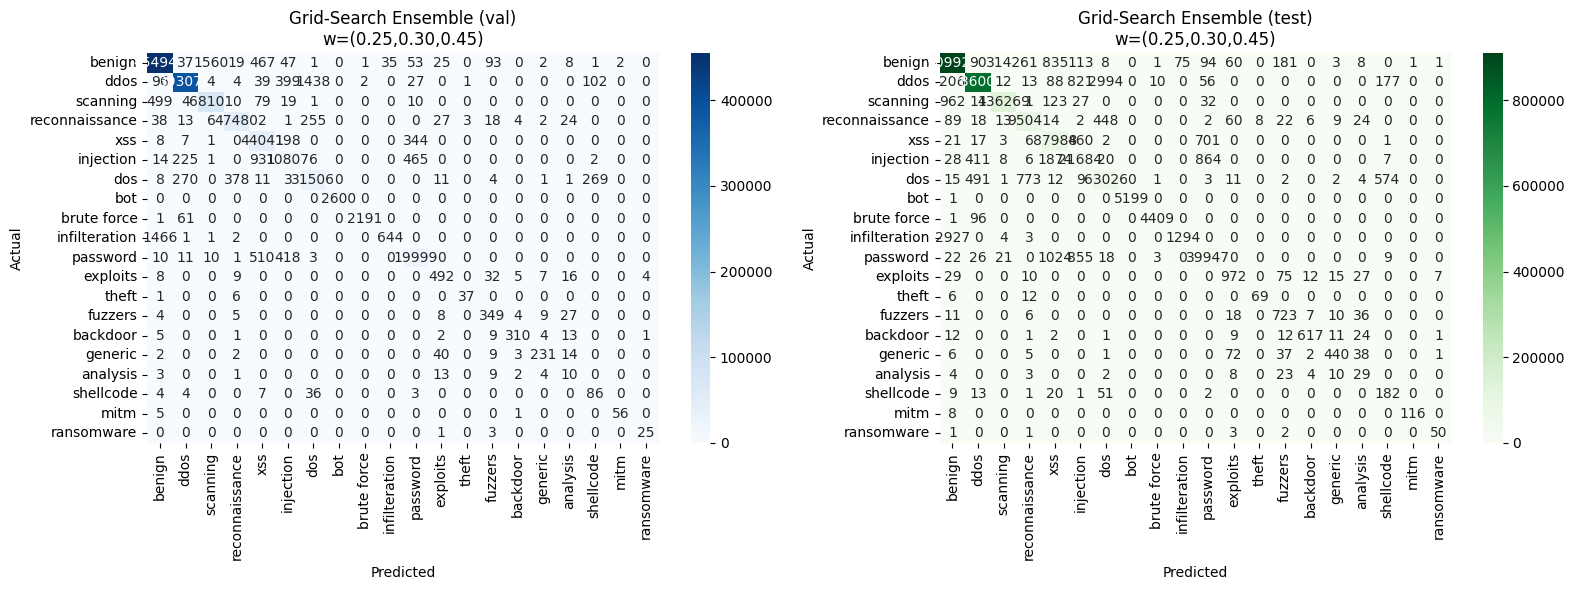


📊 Best weights: GRU=0.25, KNN=0.30, RF=0.45


In [30]:
# -----------------------------------------------------
# Confusion Matrix for Grid-Search Best Ensemble (val & test)
# -----------------------------------------------------
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Ensure full-size KNN probs exist
if "knn_val_probs" not in globals() or len(knn_val_probs) != len(y_val):
    knn_val_probs = knn.predict_proba(X_tab_val)
if "knn_test_probs" not in globals() or len(knn_test_probs) != len(y_test):
    knn_test_probs = knn.predict_proba(X_tab_test)

# Best weights from grid search
w_gru, w_knn, w_rf = best_row.w_gru, best_row.w_knn, best_row.w_rf

# Best ensemble predictions
best_val_probs = w_gru * gru_val_probs + w_knn * knn_val_probs + w_rf * rf_val_probs
best_test_probs = w_gru * gru_test_probs + w_knn * knn_test_probs + w_rf * rf_test_probs

best_val_preds = np.argmax(best_val_probs, axis=1)
best_test_preds = np.argmax(best_test_probs, axis=1)

# Confusion matrices
cm_val = confusion_matrix(y_val, best_val_preds)
cm_test = confusion_matrix(y_test, best_test_preds)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Validation
sns.heatmap(cm_val, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=class_names, yticklabels=class_names)
axes[0].set_title(f"Grid-Search Ensemble (val)\nw=({w_gru:.2f},{w_knn:.2f},{w_rf:.2f})")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Test
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Greens", ax=axes[1],
            xticklabels=class_names, yticklabels=class_names)
axes[1].set_title(f"Grid-Search Ensemble (test)\nw=({w_gru:.2f},{w_knn:.2f},{w_rf:.2f})")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

print(f"\n📊 Best weights: GRU={w_gru:.2f}, KNN={w_knn:.2f}, RF={w_rf:.2f}")

In [31]:
# =====================================================
# BHATTACHARYYA SIMILARITY: Probability Distribution Overlap
# =====================================================
# Measures how well models distinguish between class pairs
# BC = sum(sqrt(P * Q)) where P, Q are probability distributions
# Similarity in [0,1]: 1 = identical distributions, 0 = no overlap

import numpy as np
import pandas as pd

# Ensure full-size KNN probs exist
if "knn_val_probs" not in globals() or len(knn_val_probs) != len(y_val):
    knn_val_probs = knn.predict_proba(X_tab_val)
if "knn_test_probs" not in globals() or len(knn_test_probs) != len(y_test):
    knn_test_probs = knn.predict_proba(X_tab_test)

knn_val_preds = np.argmax(knn_val_probs, axis=1)
knn_test_preds = np.argmax(knn_test_probs, axis=1)

# Ensure ensemble probs exist at correct size
if "ensemble_val_probs" not in globals() or len(ensemble_val_probs) != len(y_val):
    ensemble_val_probs = (gru_val_probs + rf_val_probs + knn_val_probs) / 3.0
    ensemble_test_probs = (gru_test_probs + rf_test_probs + knn_test_probs) / 3.0
    ensemble_val_preds = np.argmax(ensemble_val_probs, axis=1)
    ensemble_test_preds = np.argmax(ensemble_test_probs, axis=1)

def bhattacharyya_coefficient_by_idx(probs, y_true, idx_a, idx_b):
    """
    Compute Bhattacharyya coefficient between predicted probability 
    distributions for two classes (by index).
    """
    y_true_arr = np.asarray(y_true)
    mask_a = (y_true_arr == idx_a)
    mask_b = (y_true_arr == idx_b)
    
    if mask_a.sum() == 0 or mask_b.sum() == 0:
        return np.nan
    
    # Mean probability distribution for samples of each class
    probs_a = probs[mask_a].mean(axis=0)
    probs_b = probs[mask_b].mean(axis=0)
    
    # Normalize to ensure they sum to 1
    probs_a = probs_a / (probs_a.sum() + 1e-10)
    probs_b = probs_b / (probs_b.sum() + 1e-10)
    
    # Bhattacharyya coefficient
    bc = np.sum(np.sqrt(probs_a * probs_b))
    return bc

def bhattacharyya_distance(bc):
    """Convert BC to Bhattacharyya distance: -ln(BC)"""
    if bc <= 0 or np.isnan(bc):
        return np.inf
    return -np.log(bc)

# Check available class names
print("Available classes:", class_names)
print("\n" + "="*70)
print("📊 BHATTACHARYYA SIMILARITY ANALYSIS")
print("="*70)

# Auto-detect Benign class (usually class 0 or contains "Benign")
benign_idx = None
for i, name in enumerate(class_names):
    if "benign" in name.lower():
        benign_idx = i
        break
if benign_idx is None:
    benign_idx = 0  # Default to first class

# Build class pairs: Benign vs all attack classes
class_pairs_idx = []
for i, name in enumerate(class_names):
    if i != benign_idx:
        class_pairs_idx.append((benign_idx, i, f"{class_names[benign_idx]} vs {name}"))

print(f"Benign class: {class_names[benign_idx]} (index {benign_idx})")
print(f"Analyzing {len(class_pairs_idx)} class pairs")

# Models to analyze
models_probs = {
    "GRU": {"val": gru_val_probs, "test": gru_test_probs},
    "RF": {"val": rf_val_probs, "test": rf_test_probs},
    "KNN": {"val": knn_val_probs, "test": knn_test_probs},
    "Ensemble (equal)": {"val": ensemble_val_probs, "test": ensemble_test_probs},
    "Ensemble (best)": {
        "val": best_row.w_gru * gru_val_probs + best_row.w_knn * knn_val_probs + best_row.w_rf * rf_val_probs,
        "test": best_row.w_gru * gru_test_probs + best_row.w_knn * knn_test_probs + best_row.w_rf * rf_test_probs,
    },
}

bc_rows = []
for model_name, splits in models_probs.items():
    for split_name, probs in splits.items():
        y_true = y_val if split_name == "val" else y_test
        
        for idx_a, idx_b, pair_name in class_pairs_idx:
            bc = bhattacharyya_coefficient_by_idx(probs, y_true, idx_a, idx_b)
            bd = bhattacharyya_distance(bc)
            separability = 1 - bc if not np.isnan(bc) else np.nan
            
            bc_rows.append({
                "model": model_name,
                "split": split_name,
                "class_pair": pair_name,
                "BC": bc,
                "BD": bd,
                "separability": separability,
            })

bc_df = pd.DataFrame(bc_rows)

if bc_df.empty or bc_df["BC"].isna().all():
    print("⚠️ No valid Bhattacharyya coefficients computed. Check class distribution.")
else:
    # Display results
    print("\n📈 Bhattacharyya Coefficients (lower = better class separation)")
    print("-"*70)
    display(
        bc_df.pivot_table(
            index=["model", "split"],
            columns="class_pair",
            values="BC",
            aggfunc="first"
        ).round(4)
    )

    print("\n📉 Separability Score (1 - BC, higher = better)")
    print("-"*70)
    display(
        bc_df.pivot_table(
            index=["model", "split"],
            columns="class_pair",
            values="separability",
            aggfunc="first"
        ).round(4)
    )

# Summary interpretation
print("\n" + "="*70)
print("📌 INTERPRETATION GUIDE")
print("="*70)
print("""
• Bhattacharyya Coefficient (BC): Measures overlap between probability distributions
  - BC ≈ 1.0: High overlap (hard to distinguish classes)
  - BC ≈ 0.0: No overlap (easy to distinguish classes)

• Separability = 1 - BC
  - Higher separability indicates better class discrimination
  
• Lower BC / Higher Separability → Model better distinguishes attack from benign
""")

Available classes: ['benign', 'ddos', 'scanning', 'reconnaissance', 'xss', 'injection', 'dos', 'bot', 'brute force', 'infilteration', 'password', 'exploits', 'theft', 'fuzzers', 'backdoor', 'generic', 'analysis', 'shellcode', 'mitm', 'ransomware']

📊 BHATTACHARYYA SIMILARITY ANALYSIS
Benign class: benign (index 0)
Analyzing 19 class pairs

📈 Bhattacharyya Coefficients (lower = better class separation)
----------------------------------------------------------------------


class_pair              benign vs analysis  benign vs backdoor  benign vs bot  \
model            split                                                          
Ensemble (best)  test               0.2209              0.1349         0.0249   
                 val                0.3000              0.1188         0.0278   
Ensemble (equal) test               0.2313              0.1428         0.0247   
                 val                0.3128              0.1276         0.0269   
GRU              test               0.2432              0.1735         0.0139   
                 val                0.3189              0.1559         0.0024   
KNN              test               0.2610              0.1397         0.0307   
                 val                0.3646              0.1334         0.0345   
RF               test               0.1476              0.0914         0.0216   
                 val                0.2112              0.0615         0.0277   

class_pair              benign vs brute force  benign vs ddos  benign vs dos  \
model            split                                                         
Ensemble (best)  test                  0.0362          0.0481         0.0484   
                 val                   0.0431          0.0476         0.0498   
Ensemble (equal) test                  0.0366          0.0454         0.0461   
                 val                   0.0444          0.0449         0.0476   
GRU              test                  0.0361          0.0375         0.0345   
                 val                   0.0458          0.0371         0.0384   
KNN              test                  0.0358          0.0367         0.0382   
                 val                   0.0468          0.0361         0.0374   
RF               test                  0.0326          0.0597         0.0567   
                 val                   0.0344          0.0592         0.0580   

class_pair              benign vs exploits  benign vs fuzzers  \
model            split                                          
Ensemble (best)  test               0.3627             0.2959   
                 val                0.3438             0.2760   
Ensemble (equal) test               0.3870             0.3113   
                 val                0.3674             0.2909   
GRU              test               0.3567             0.3379   
                 val                0.3498             0.3194   
KNN              test               0.5437             0.3564   
                 val                0.5070             0.3286   
RF               test               0.1512             0.1961   
                 val                0.1395             0.1792   

class_pair              benign vs generic  benign vs infilteration  \
model            split                                               
Ensemble (best)  test              0.1948                   0.8816   
                 val               0.2010                   0.8814   
Ensemble (equal) test              0.2085                   0.8931   
                 val               0.2141                   0.8929   
GRU              test              0.2212                   0.9061   
                 val               0.1980                   0.9051   
KNN              test              0.2628                   0.8790   
                 val               0.2944                   0.8809   
RF               test              0.0933                   0.7929   
                 val               0.0854                   0.7917   

class_pair              benign vs injection  benign vs mitm  \
model            split                                        
Ensemble (best)  test                0.1233          0.3310   
                 val                 0.1206          0.3726   
Ensemble (equal) test                0.1239          0.3525   
                 val                 0.1207          0.3952   
GRU              test                0.1175          0.4256   
   


📉 Separability Score (1 - BC, higher = better)
----------------------------------------------------------------------


class_pair              benign vs analysis  benign vs backdoor  benign vs bot  \
model            split                                                          
Ensemble (best)  test               0.7791              0.8651         0.9751   
                 val                0.7000              0.8812         0.9722   
Ensemble (equal) test               0.7687              0.8572         0.9753   
                 val                0.6872              0.8724         0.9731   
GRU              test               0.7568              0.8265         0.9861   
                 val                0.6811              0.8441         0.9976   
KNN              test               0.7390              0.8603         0.9693   
                 val                0.6354              0.8666         0.9655   
RF               test               0.8524              0.9086         0.9784   
                 val                0.7888              0.9385         0.9723   

class_pair              benign vs brute force  benign vs ddos  benign vs dos  \
model            split                                                         
Ensemble (best)  test                  0.9638          0.9519         0.9516   
                 val                   0.9569          0.9524         0.9502   
Ensemble (equal) test                  0.9634          0.9546         0.9539   
                 val                   0.9556          0.9551         0.9524   
GRU              test                  0.9639          0.9625         0.9655   
                 val                   0.9542          0.9629         0.9616   
KNN              test                  0.9642          0.9633         0.9618   
                 val                   0.9532          0.9639         0.9626   
RF               test                  0.9674          0.9403         0.9433   
                 val                   0.9656          0.9408         0.9420   

class_pair              benign vs exploits  benign vs fuzzers  \
model            split                                          
Ensemble (best)  test               0.6373             0.7041   
                 val                0.6562             0.7240   
Ensemble (equal) test               0.6130             0.6887   
                 val                0.6326             0.7091   
GRU              test               0.6433             0.6621   
                 val                0.6502             0.6806   
KNN              test               0.4563             0.6436   
                 val                0.4930             0.6714   
RF               test               0.8488             0.8039   
                 val                0.8605             0.8208   

class_pair              benign vs generic  benign vs infilteration  \
model            split                                               
Ensemble (best)  test              0.8052                   0.1184   
                 val               0.7990                   0.1186   
Ensemble (equal) test              0.7915                   0.1069   
                 val               0.7859                   0.1071   
GRU              test              0.7788                   0.0939   
                 val               0.8020                   0.0949   
KNN              test              0.7372                   0.1210   
                 val               0.7056                   0.1191   
RF               test              0.9067                   0.2071   
                 val               0.9146                   0.2083   

class_pair              benign vs injection  benign vs mitm  \
model            split                                        
Ensemble (best)  test                0.8767          0.6690   
                 val                 0.8794          0.6274   
Ensemble (equal) test                0.8761          0.6475   
                 val                 0.8793          0.6048   
GRU              test                0.8825          0.5744   
   


📌 INTERPRETATION GUIDE

• Bhattacharyya Coefficient (BC): Measures overlap between probability distributions
  - BC ≈ 1.0: High overlap (hard to distinguish classes)
  - BC ≈ 0.0: No overlap (easy to distinguish classes)

• Separability = 1 - BC
  - Higher separability indicates better class discrimination
  
• Lower BC / Higher Separability → Model better distinguishes attack from benign



In [32]:
# -----------------------------------------------------
# 🔧 ALIGN ALL VALIDATION DATA TO SHARED EVAL SET
# -----------------------------------------------------
USE_SHARED_EVAL = True  # set False if you want full val/test

if USE_SHARED_EVAL:
    y_val_used = y_eval
    gru_val_preds_used = gru_eval_preds
    gru_val_probs_used = gru_eval_probs
    rf_val_preds_used = rf_eval_preds
    rf_val_probs_used = rf_eval_probs
    knn_val_preds_used = knn_eval_preds
    knn_val_probs_used = knn_eval_probs
    ensemble_val_preds_used = ensemble_eval_preds
    ensemble_val_probs_used = ensemble_eval_probs
    best_val_preds_used = best_val_preds[eval_idx]
    best_val_probs_used = best_val_probs[eval_idx]
else:
    y_val_used = y_val
    gru_val_preds_used = gru_val_preds
    gru_val_probs_used = gru_val_probs
    rf_val_preds_used = rf_val_preds
    rf_val_probs_used = rf_val_probs
    knn_val_preds_used = knn_val_preds
    knn_val_probs_used = knn_val_probs
    ensemble_val_preds_used = ensemble_val_preds
    ensemble_val_probs_used = ensemble_val_probs
    best_val_preds_used = best_val_preds
    best_val_probs_used = best_val_probs


NameError: name 'gru_eval_preds' is not defined

In [33]:
# =====================================================
# COMPREHENSIVE EVALUATION MATRIX FOR THESIS
# =====================================================
# All models, all metrics, publication-ready format

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, cohen_kappa_score, matthews_corrcoef,
    balanced_accuracy_score, roc_auc_score, log_loss
)

print("="*80)
print("📊 COMPREHENSIVE MODEL EVALUATION MATRIX (THESIS-READY)")
print("="*80)

# Ensure full-size KNN probs/preds exist
if "knn_val_probs" not in globals() or len(knn_val_probs) != len(y_val):
    knn_val_probs = knn.predict_proba(X_tab_val)
if "knn_test_probs" not in globals() or len(knn_test_probs) != len(y_test):
    knn_test_probs = knn.predict_proba(X_tab_test)

knn_val_preds = np.argmax(knn_val_probs, axis=1)
knn_test_preds = np.argmax(knn_test_probs, axis=1)

# Ensure ensemble probs/preds exist at correct size
if "ensemble_val_probs" not in globals() or len(ensemble_val_probs) != len(y_val):
    ensemble_val_probs = (gru_val_probs + rf_val_probs + knn_val_probs) / 3.0
    ensemble_test_probs = (gru_test_probs + rf_test_probs + knn_test_probs) / 3.0
    ensemble_val_preds = np.argmax(ensemble_val_probs, axis=1)
    ensemble_test_preds = np.argmax(ensemble_test_probs, axis=1)

# Ensure best ensemble probs/preds exist at correct size
if "best_val_probs" not in globals() or len(best_val_probs) != len(y_val):
    w_gru, w_knn, w_rf = best_row.w_gru, best_row.w_knn, best_row.w_rf
    best_val_probs = w_gru * gru_val_probs + w_knn * knn_val_probs + w_rf * rf_val_probs
    best_test_probs = w_gru * gru_test_probs + w_knn * knn_test_probs + w_rf * rf_test_probs
    best_val_preds = np.argmax(best_val_probs, axis=1)
    best_test_preds = np.argmax(best_test_probs, axis=1)

def compute_comprehensive_metrics(y_true, y_pred, y_probs, model_name, split_name, class_names):
    """
    Compute all standard classification metrics for thesis reporting.
    """
    n_classes = len(class_names)
    
    # Basic metrics
    acc = accuracy_score(y_true, y_pred)
    balanced_acc = balanced_accuracy_score(y_true, y_pred)
    
    # Macro/Micro/Weighted averages
    prec_macro = precision_score(y_true, y_pred, average='macro', zero_division=0)
    prec_micro = precision_score(y_true, y_pred, average='micro', zero_division=0)
    prec_weighted = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    
    recall_macro = recall_score(y_true, y_pred, average='macro', zero_division=0)
    recall_micro = recall_score(y_true, y_pred, average='micro', zero_division=0)
    recall_weighted = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    
    f1_macro = f1_score(y_true, y_pred, average='macro', zero_division=0)
    f1_micro = f1_score(y_true, y_pred, average='micro', zero_division=0)
    f1_weighted = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    
    # Cohen's Kappa & MCC (robust metrics)
    kappa = cohen_kappa_score(y_true, y_pred)
    mcc = matthews_corrcoef(y_true, y_pred)
    
    # Confusion matrix derived metrics
    cm = confusion_matrix(y_true, y_pred)
    tp = np.diag(cm)
    fn = cm.sum(axis=1) - tp
    fp = cm.sum(axis=0) - tp
    tn = cm.sum() - (tp + fp + fn)
    
    # Overall FPR/FNR
    fpr_overall = fp.sum() / (fp.sum() + tn.sum() + 1e-10)
    fnr_overall = fn.sum() / (fn.sum() + tp.sum() + 1e-10)
    
    # Detection Rate (DR) = TPR = Recall
    detection_rate = tp.sum() / (tp.sum() + fn.sum() + 1e-10)
    
    # False Alarm Rate (FAR) = FPR
    false_alarm_rate = fpr_overall
    
    # AUC-ROC (One-vs-Rest)
    try:
        auc_ovr = roc_auc_score(y_true, y_probs, multi_class='ovr', average='macro')
    except:
        auc_ovr = np.nan
    
    # Log Loss
    try:
        logloss = log_loss(y_true, y_probs)
    except:
        logloss = np.nan
    
    return {
        "Model": model_name,
        "Split": split_name,
        "Accuracy": acc,
        "Balanced Accuracy": balanced_acc,
        "Precision (Macro)": prec_macro,
        "Precision (Micro)": prec_micro,
        "Precision (Weighted)": prec_weighted,
        "Recall (Macro)": recall_macro,
        "Recall (Micro)": recall_micro,
        "Recall (Weighted)": recall_weighted,
        "F1-Score (Macro)": f1_macro,
        "F1-Score (Micro)": f1_micro,
        "F1-Score (Weighted)": f1_weighted,
        "Cohen's Kappa": kappa,
        "MCC": mcc,
        "FPR (Overall)": fpr_overall,
        "FNR (Overall)": fnr_overall,
        "Detection Rate": detection_rate,
        "False Alarm Rate": false_alarm_rate,
        "AUC-ROC (Macro OvR)": auc_ovr,
        "Log Loss": logloss,
    }

# Prepare all models
all_models = {
    "GRU": {
        "val": {"preds": gru_val_preds, "probs": gru_val_probs},
        "test": {"preds": gru_test_preds, "probs": gru_test_probs},
    },
    "Random Forest": {
        "val": {"preds": rf_val_preds, "probs": rf_val_probs},
        "test": {"preds": rf_test_preds, "probs": rf_test_probs},
    },
    "KNN": {
        "val": {"preds": knn_val_preds, "probs": knn_val_probs},
        "test": {"preds": knn_test_preds, "probs": knn_test_probs},
    },
    "Ensemble (Equal Weights)": {
        "val": {"preds": ensemble_val_preds, "probs": ensemble_val_probs},
        "test": {"preds": ensemble_test_preds, "probs": ensemble_test_probs},
    },
    f"Ensemble (Optimized: {best_row.w_gru:.2f}/{best_row.w_knn:.2f}/{best_row.w_rf:.2f})": {
        "val": {
            "preds": best_val_preds,
            "probs": best_val_probs,
        },
        "test": {
            "preds": best_test_preds,
            "probs": best_test_probs,
        },
    },
}

# Compute metrics for all models
comprehensive_rows = []
for model_name, splits in all_models.items():
    for split_name, data in splits.items():
        y_true = y_val if split_name == "val" else y_test
        metrics = compute_comprehensive_metrics(
            y_true=y_true,
            y_pred=data["preds"],
            y_probs=data["probs"],
            model_name=model_name,
            split_name=split_name,
            class_names=class_names,
        )
        comprehensive_rows.append(metrics)

comprehensive_df = pd.DataFrame(comprehensive_rows)

# Display: Main metrics table
print("\n📋 TABLE 1: Overall Classification Performance")
print("-"*80)
main_metrics = ["Accuracy", "Balanced Accuracy", "F1-Score (Macro)", "F1-Score (Weighted)", 
                "Cohen's Kappa", "MCC", "AUC-ROC (Macro OvR)"]
display(
    comprehensive_df[["Model", "Split"] + main_metrics]
    .set_index(["Model", "Split"])
    .round(4)
    .style.format("{:.4f}")
    .background_gradient(cmap="RdYlGn", subset=main_metrics)
)

print("\n📋 TABLE 2: Precision, Recall, F1 (All Averaging Methods)")
print("-"*80)
prf_metrics = ["Precision (Macro)", "Precision (Weighted)", 
               "Recall (Macro)", "Recall (Weighted)",
               "F1-Score (Macro)", "F1-Score (Weighted)"]
display(
    comprehensive_df[["Model", "Split"] + prf_metrics]
    .set_index(["Model", "Split"])
    .round(4)
    .style.format("{:.4f}")
    .background_gradient(cmap="RdYlGn", subset=prf_metrics)
)

print("\n📋 TABLE 3: Error Rates & Detection Performance")
print("-"*80)
error_metrics = ["FPR (Overall)", "FNR (Overall)", "Detection Rate", "False Alarm Rate", "Log Loss"]
display(
    comprehensive_df[["Model", "Split"] + error_metrics]
    .set_index(["Model", "Split"])
    .round(4)
    .style.format("{:.4f}")
    .background_gradient(cmap="RdYlGn_r", subset=["FPR (Overall)", "FNR (Overall)", "False Alarm Rate", "Log Loss"])
    .background_gradient(cmap="RdYlGn", subset=["Detection Rate"])
)

# Test set comparison (for thesis results table)
print("\n" + "="*80)
print("📊 THESIS SUMMARY TABLE: TEST SET COMPARISON")
print("="*80)
test_summary = comprehensive_df[comprehensive_df["Split"] == "test"].copy()
test_summary = test_summary.set_index("Model").drop(columns=["Split"])
display(test_summary.round(4).T.style.format("{:.4f}").background_gradient(axis=1, cmap="RdYlGn"))

📊 COMPREHENSIVE MODEL EVALUATION MATRIX (THESIS-READY)


d:\Pycode\Test\compile_pipeline\.venv\lib\site-packages\sklearn\metrics\_classification.py:259: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
d:\Pycode\Test\compile_pipeline\.venv\lib\site-packages\sklearn\metrics\_classification.py:259: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
d:\Pycode\Test\compile_pipeline\.venv\lib\site-packages\sklearn\metrics\_classification.py:259: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
d:\Pycode\Test\compile_pipeline\.venv\lib\site-packages\sklearn\metrics\_classification.py:259: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(



📋 TABLE 1: Overall Classification Performance
--------------------------------------------------------------------------------



📋 TABLE 2: Precision, Recall, F1 (All Averaging Methods)
--------------------------------------------------------------------------------



📋 TABLE 3: Error Rates & Detection Performance
--------------------------------------------------------------------------------



📊 THESIS SUMMARY TABLE: TEST SET COMPARISON


Model,GRU,Random Forest,KNN,Ensemble (Equal Weights),Ensemble (Optimized: 0.25/0.30/0.45)
Accuracy,0.9862,0.9171,0.9862,0.9894,0.9895
Balanced Accuracy,0.7321,0.9349,0.7500,0.8219,0.8505
Precision (Macro),0.8288,0.7799,0.8325,0.8618,0.8520
Precision (Micro),0.9862,0.9171,0.9862,0.9894,0.9895
Precision (Weighted),0.9863,0.9862,0.9859,0.9895,0.9898
Recall (Macro),0.7321,0.9349,0.7500,0.8219,0.8505
Recall (Micro),0.9862,0.9171,0.9862,0.9894,0.9895
Recall (Weighted),0.9862,0.9171,0.9862,0.9894,0.9895
F1-Score (Macro),0.7517,0.8051,0.7783,0.8296,0.8334
F1-Score (Micro),0.9862,0.9171,0.9862,0.9894,0.9895


In [34]:
%pip install jinja2

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'd:\Pycode\Test\compile_pipeline\.venv\Scripts\python.exe -m pip install --upgrade pip' command.


In [35]:
# =====================================================
# PER-CLASS METRICS FOR THESIS (All Models, Test Set)
# =====================================================
from sklearn.metrics import classification_report, precision_recall_fscore_support
import pandas as pd
import numpy as np

print("="*80)
print("📊 PER-CLASS PERFORMANCE METRICS (TEST SET)")
print("="*80)

# Ensure full-size KNN test preds exist
if "knn_test_probs" not in globals() or len(knn_test_probs) != len(y_test):
    knn_test_probs = knn.predict_proba(X_tab_test)
knn_test_preds = np.argmax(knn_test_probs, axis=1)

# Ensure ensemble test preds exist at correct size
if "ensemble_test_probs" not in globals() or len(ensemble_test_probs) != len(y_test):
    if "knn_val_probs" not in globals() or len(knn_val_probs) != len(y_val):
        knn_val_probs = knn.predict_proba(X_tab_val)
    ensemble_val_probs = (gru_val_probs + rf_val_probs + knn_val_probs) / 3.0
    ensemble_test_probs = (gru_test_probs + rf_test_probs + knn_test_probs) / 3.0
    ensemble_val_preds = np.argmax(ensemble_val_probs, axis=1)
    ensemble_test_preds = np.argmax(ensemble_test_probs, axis=1)

# Ensure best test preds exist at correct size
if "best_test_probs" not in globals() or len(best_test_probs) != len(y_test):
    w_gru, w_knn, w_rf = best_row.w_gru, best_row.w_knn, best_row.w_rf
    if "knn_val_probs" not in globals() or len(knn_val_probs) != len(y_val):
        knn_val_probs = knn.predict_proba(X_tab_val)
    best_val_probs = w_gru * gru_val_probs + w_knn * knn_val_probs + w_rf * rf_val_probs
    best_test_probs = w_gru * gru_test_probs + w_knn * knn_test_probs + w_rf * rf_test_probs
    best_val_preds = np.argmax(best_val_probs, axis=1)
    best_test_preds = np.argmax(best_test_probs, axis=1)

def get_per_class_metrics(y_true, y_pred, class_names, model_name):
    """Extract per-class precision, recall, F1, support."""
    prec, rec, f1, sup = precision_recall_fscore_support(
        y_true, y_pred, 
        labels=np.arange(len(class_names)),
        zero_division=0
    )
    
    rows = []
    for i, cls in enumerate(class_names):
        rows.append({
            "Model": model_name,
            "Class": cls,
            "Precision": prec[i],
            "Recall": rec[i],
            "F1-Score": f1[i],
            "Support": int(sup[i]),
        })
    return rows

# Collect per-class metrics for all models (test set)
per_class_all = []
test_models = {
    "GRU": gru_test_preds,
    "RF": rf_test_preds,
    "KNN": knn_test_preds,
    "Ensemble (Equal)": ensemble_test_preds,
    "Ensemble (Best)": best_test_preds,
}

for model_name, preds in test_models.items():
    per_class_all.extend(get_per_class_metrics(y_test, preds, class_names, model_name))

per_class_df = pd.DataFrame(per_class_all)

# Pivot for comparison
print("\n📋 TABLE 4: Per-Class Precision (Test Set)")
print("-"*80)
display(
    per_class_df.pivot_table(
        index="Class", 
        columns="Model", 
        values="Precision"
    ).round(4)
    .style.format("{:.4f}")
    .background_gradient(cmap="RdYlGn", axis=1)
)

print("\n📋 TABLE 5: Per-Class Recall (Test Set)")
print("-"*80)
display(
    per_class_df.pivot_table(
        index="Class", 
        columns="Model", 
        values="Recall"
    ).round(4)
    .style.format("{:.4f}")
    .background_gradient(cmap="RdYlGn", axis=1)
)

print("\n📋 TABLE 6: Per-Class F1-Score (Test Set)")
print("-"*80)
display(
    per_class_df.pivot_table(
        index="Class", 
        columns="Model", 
        values="F1-Score"
    ).round(4)
    .style.format("{:.4f}")
    .background_gradient(cmap="RdYlGn", axis=1)
)

# Class support (sample counts)
print("\n📋 TABLE 7: Class Distribution (Support)")
print("-"*80)
support_df = per_class_df[per_class_df["Model"] == "GRU"][["Class", "Support"]]
display(support_df.set_index("Class"))

# Per-class FPR/FNR for best model
print("\n📋 TABLE 8: Per-Class FPR & FNR (Best Ensemble, Test Set)")
print("-"*80)

cm_best = confusion_matrix(y_test, best_test_preds)
tp = np.diag(cm_best)
fn = cm_best.sum(axis=1) - tp
fp = cm_best.sum(axis=0) - tp
tn = cm_best.sum() - (tp + fp + fn)

fpr_per_class = fp / (fp + tn + 1e-10)
fnr_per_class = fn / (fn + tp + 1e-10)

fpr_fnr_df = pd.DataFrame({
    "Class": class_names,
    "FPR": fpr_per_class,
    "FNR": fnr_per_class,
    "TP": tp,
    "FP": fp,
    "FN": fn,
    "TN": tn,
})
display(
    fpr_fnr_df.set_index("Class")
    .round(4)
    .style.format({"FPR": "{:.4f}", "FNR": "{:.4f}", "TP": "{:.0f}", "FP": "{:.0f}", "FN": "{:.0f}", "TN": "{:.0f}"})
    .background_gradient(cmap="RdYlGn_r", subset=["FPR", "FNR"])
)

print("\n" + "="*80)
print("✅ All thesis-ready evaluation tables generated")
print("="*80)

📊 PER-CLASS PERFORMANCE METRICS (TEST SET)

📋 TABLE 4: Per-Class Precision (Test Set)
--------------------------------------------------------------------------------


Model,Ensemble (Best),Ensemble (Equal),GRU,KNN,RF
Class,,,,,
analysis,0.1526,0.1395,0.0000,0.1333,0.1655
backdoor,0.9522,0.9434,0.9902,0.9254,0.9779
benign,0.9952,0.9946,0.9922,0.9912,0.9992
bot,1.0000,1.0000,1.0000,1.0000,1.0000
brute force,0.9966,0.9968,0.9912,0.9910,0.6067
ddos,0.9985,0.9981,0.9970,0.9960,0.9996
dos,0.9467,0.9480,0.9317,0.9691,0.9181
exploits,0.8013,0.7907,0.7608,0.6734,0.8406
fuzzers,0.6713,0.6472,0.4428,0.5671,0.7376



📋 TABLE 5: Per-Class Recall (Test Set)
--------------------------------------------------------------------------------


Model,Ensemble (Best),Ensemble (Equal),GRU,KNN,RF
Class,,,,,
analysis,0.3494,0.2169,0.0000,0.0964,0.8675
backdoor,0.8942,0.8942,0.8797,0.8986,0.8986
benign,0.9949,0.9952,0.9949,0.9928,0.8278
bot,0.9998,0.9998,0.9998,0.9992,1.0000
brute force,0.9785,0.9783,0.9774,0.9780,0.9956
ddos,0.9945,0.9949,0.9949,0.9970,0.9853
dos,0.9708,0.9730,0.9488,0.9539,0.9747
exploits,0.8474,0.8265,0.7210,0.5214,0.8692
fuzzers,0.8915,0.8866,0.9075,0.6252,0.8977



📋 TABLE 6: Per-Class F1-Score (Test Set)
--------------------------------------------------------------------------------


Model,Ensemble (Best),Ensemble (Equal),GRU,KNN,RF
Class,,,,,
analysis,0.2125,0.1698,0.0000,0.1119,0.2780
backdoor,0.9223,0.9182,0.9317,0.9118,0.9366
benign,0.9951,0.9949,0.9936,0.9920,0.9055
bot,0.9999,0.9999,0.9999,0.9996,1.0000
brute force,0.9875,0.9875,0.9842,0.9845,0.7539
ddos,0.9965,0.9965,0.9959,0.9965,0.9924
dos,0.9586,0.9603,0.9402,0.9614,0.9456
exploits,0.8237,0.8082,0.7404,0.5877,0.8547
fuzzers,0.7659,0.7482,0.5952,0.5947,0.8098



📋 TABLE 7: Class Distribution (Support)
--------------------------------------------------------------------------------


,Support
Class,
benign,914597
ddos,790382
scanning,137428
reconnaissance,95746
xss,89199
injection,24902
dos,64924
bot,5200
brute force,4506



📋 TABLE 8: Per-Class FPR & FNR (Best Ensemble, Test Set)
--------------------------------------------------------------------------------


,FPR,FNR,TP,FP,FN,TN
Class,,,,,,
benign,0.0035,0.0051,909924,4358,4673,1257962
ddos,0.0008,0.0055,786005,1176,4377,1385359
scanning,0.0016,0.0084,136269,3204,1159,2036285
reconnaissance,0.0004,0.0074,95041,902,705,2080269
xss,0.0019,0.0136,87988,3982,1211,2083736
injection,0.0011,0.1292,21684,2288,3218,2149727
dos,0.0017,0.0292,63026,3545,1898,2108448
bot,0.0000,0.0002,5199,0,1,2171717
brute force,0.0000,0.0215,4409,15,97,2172396



✅ All thesis-ready evaluation tables generated


📊 FALSE NEGATIVE / FALSE POSITIVE TRADE-OFF ANALYSIS

📋 TABLE 1: Overall FN/FP Cost Analysis
   Cost Formula: 10.0×FN + 1.0×FP (lower is better)
--------------------------------------------------------------------------------


,Total TP,Total FP,Total FN,Total TN,FPR (%),FNR (%),Cost (FN×10 + FP)
Model,,,,,,,
Ensemble (Best),"197,881","2,119","2,119","3,797,881",0.06%,1.06%,"23,309"
Ensemble (Equal),"197,860","2,140","2,140","3,797,860",0.06%,1.07%,"23,540"
KNN,"197,193","2,807","2,807","3,797,193",0.07%,1.40%,"30,877"
GRU,"197,193","2,807","2,807","3,797,193",0.07%,1.40%,"30,877"
RF,"183,642","16,358","16,358","3,783,642",0.43%,8.18%,"179,938"


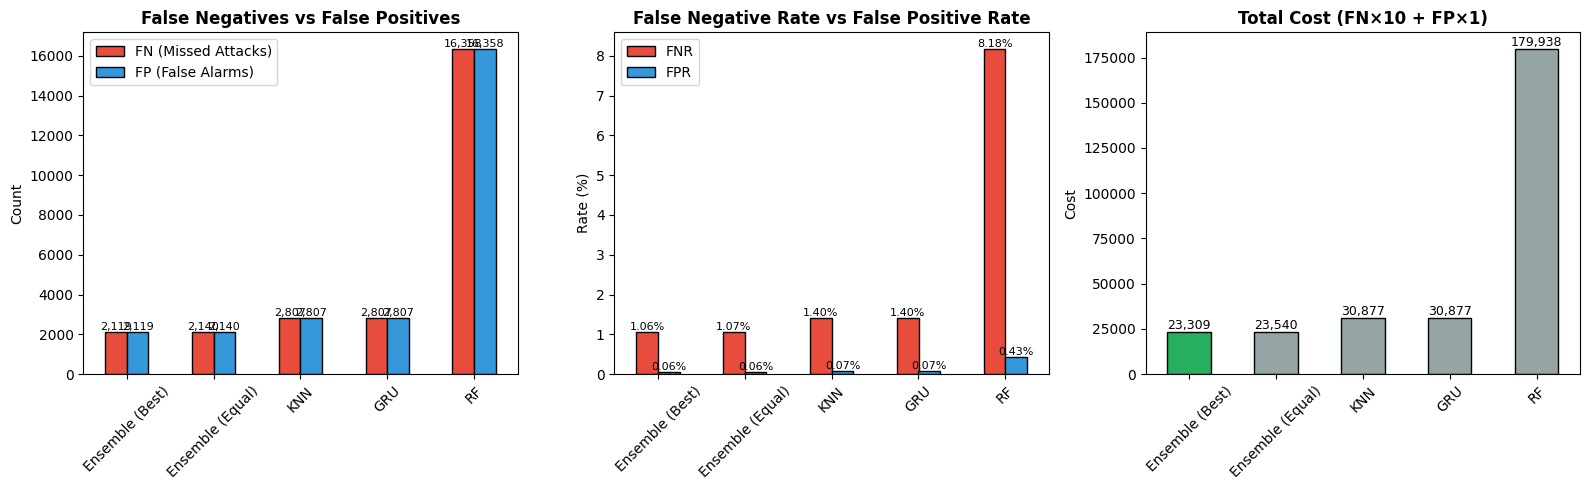


📋 TABLE 2: Per-Class False Positive Rate (FPR)
--------------------------------------------------------------------------------


Model,Ensemble (Best),Ensemble (Equal),GRU,KNN,RF
Class,,,,,
analysis,0.0001,0.0001,0.0000,0.0000,0.0002
backdoor,0.0000,0.0000,0.0000,0.0000,0.0000
benign,0.0032,0.0037,0.0056,0.0060,0.0003
bot,0.0000,0.0000,0.0000,0.0000,0.0000
brute force,0.0000,0.0000,0.0000,0.0000,0.0014
ddos,0.0010,0.0013,0.0019,0.0025,0.0003
dos,0.0016,0.0016,0.0021,0.0009,0.0026
exploits,0.0001,0.0001,0.0001,0.0001,0.0001
fuzzers,0.0002,0.0002,0.0005,0.0002,0.0001



📋 TABLE 3: Per-Class False Negative Rate (FNR)
--------------------------------------------------------------------------------


Model,Ensemble (Best),Ensemble (Equal),GRU,KNN,RF
Class,,,,,
analysis,0.7500,0.7500,1.0000,1.0000,0.1250
backdoor,0.1429,0.1429,0.1746,0.1429,0.1111
benign,0.0052,0.0049,0.0052,0.0077,0.1692
bot,0.0000,0.0000,0.0000,0.0042,0.0000
brute force,0.0362,0.0362,0.0386,0.0386,0.0145
ddos,0.0053,0.0049,0.0050,0.0027,0.0148
dos,0.0295,0.0285,0.0525,0.0468,0.0251
exploits,0.1905,0.2190,0.2857,0.4952,0.1905
fuzzers,0.1200,0.1467,0.0800,0.3200,0.1467


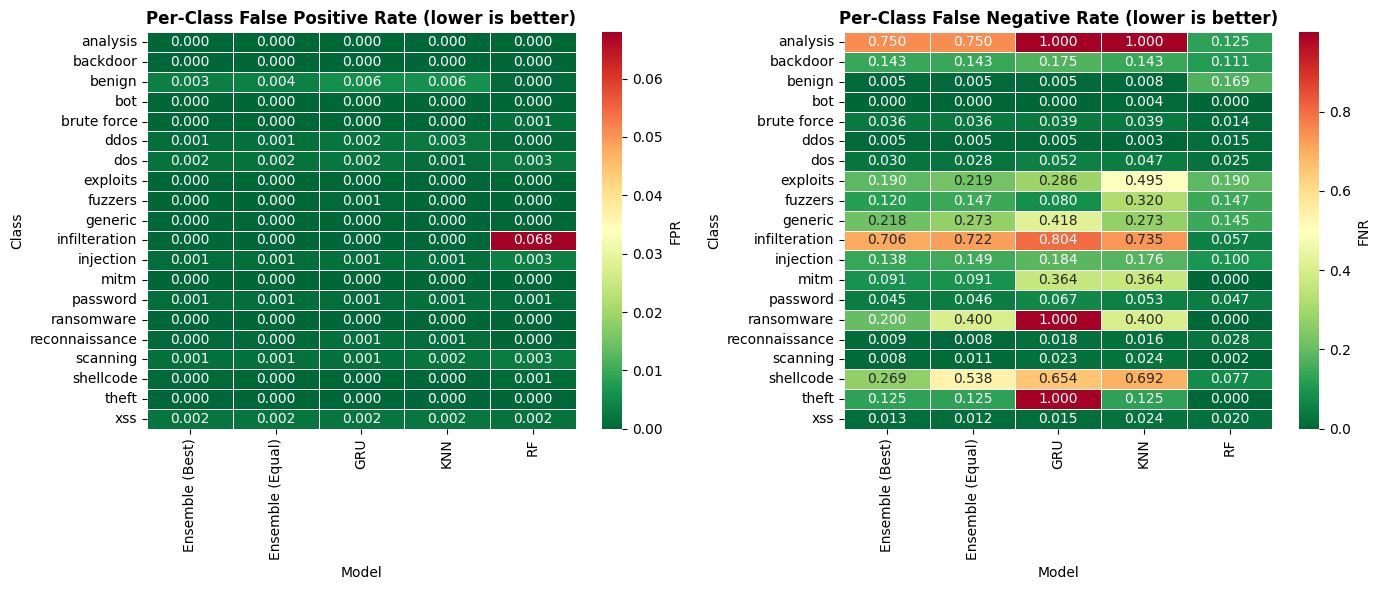


📌 SUMMARY
✅ Lowest Cost Model: Ensemble (Best)
✅ Lowest FNR Model: Ensemble (Best) (fewer missed attacks)
✅ Lowest FPR Model: Ensemble (Best) (fewer false alarms)


In [36]:
# =====================================================
# FN/FP TRADE-OFF ANALYSIS WITH VISUALIZATION
# =====================================================
FN_COST = 10.0
FP_COST = 1.0

from sklearn.metrics import confusion_matrix
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("="*80)
print("📊 FALSE NEGATIVE / FALSE POSITIVE TRADE-OFF ANALYSIS")
print("="*80)

# Ensure eval_idx and y_eval exist
if "eval_idx" not in globals() or "y_eval" not in globals():
    from sklearn.model_selection import StratifiedShuffleSplit
    EVAL_SIZE = 200_000
    RANDOM_STATE = 42
    sss = StratifiedShuffleSplit(n_splits=1, test_size=EVAL_SIZE, random_state=RANDOM_STATE)
    for _, eval_idx in sss.split(X_tab_val, y_val):
        X_eval = X_tab_val[eval_idx]
        y_eval = y_val.iloc[eval_idx] if hasattr(y_val, "iloc") else y_val[eval_idx]
    print(f"✅ Created shared eval set: {len(y_eval)} samples")

label_list = sorted(np.unique(y_eval))
label_names = class_names if 'class_names' in globals() else [str(l) for l in label_list]

def confusion_stats(y_true, preds, labels):
    cm = confusion_matrix(y_true, preds, labels=labels)
    tp = np.diag(cm)
    fn = cm.sum(axis=1) - tp
    fp = cm.sum(axis=0) - tp
    tn = cm.sum() - tp - fn - fp
    fpr = fp / (fp + tn + 1e-9)
    fnr = fn / (fn + tp + 1e-9)
    return tp, fp, fn, tn, fpr, fnr

# Predictions ON SHARED EVAL SET
gru_eval_probs = gru_val_probs[eval_idx]
rf_eval_probs = rf_val_probs[eval_idx]
knn_eval_probs = knn.predict_proba(X_eval)

gru_eval_preds = np.argmax(gru_eval_probs, axis=1)
rf_eval_preds = np.argmax(rf_eval_probs, axis=1)
knn_eval_preds = np.argmax(knn_eval_probs, axis=1)

ensemble_eval_probs = (gru_eval_probs + rf_eval_probs + knn_eval_probs) / 3.0
ensemble_eval_preds = np.argmax(ensemble_eval_probs, axis=1)

model_preds = {
    "GRU": gru_eval_preds,
    "RF": rf_eval_preds,
    "KNN": knn_eval_preds,
    "Ensemble (Equal)": ensemble_eval_preds,
}

if "best_row" in globals():
    w_gru, w_knn, w_rf = best_row.w_gru, best_row.w_knn, best_row.w_rf
    best_eval_probs = w_gru * gru_eval_probs + w_knn * knn_eval_probs + w_rf * rf_eval_probs
    best_eval_preds = np.argmax(best_eval_probs, axis=1)
    model_preds["Ensemble (Best)"] = best_eval_preds

# Compute stats for all models
cost_rows = []
per_class_rows = []

for model_name, preds in model_preds.items():
    tp, fp, fn, tn, fpr, fnr = confusion_stats(y_eval, preds, label_list)
    
    total_fn = fn.sum()
    total_fp = fp.sum()
    total_tp = tp.sum()
    total_tn = tn.sum()
    cost = FN_COST * total_fn + FP_COST * total_fp
    
    overall_fpr = total_fp / (total_fp + total_tn + 1e-9)
    overall_fnr = total_fn / (total_fn + total_tp + 1e-9)
    
    cost_rows.append({
        "Model": model_name,
        "Total TP": int(total_tp),
        "Total FP": int(total_fp),
        "Total FN": int(total_fn),
        "Total TN": int(total_tn),
        "FPR (%)": overall_fpr * 100,
        "FNR (%)": overall_fnr * 100,
        "Cost (FN×10 + FP)": float(cost),
    })
    
    for i, cls in enumerate(label_list):
        per_class_rows.append({
            "Model": model_name,
            "Class": label_names[i],
            "FPR": fpr[i],
            "FNR": fnr[i],
            "TP": tp[i],
            "FP": fp[i],
            "FN": fn[i],
        })

cost_df = pd.DataFrame(cost_rows).sort_values("Cost (FN×10 + FP)")
per_class_df = pd.DataFrame(per_class_rows)

# -----------------------------------------------------
# TABLE 1: Overall Cost Analysis
# -----------------------------------------------------
print("\n📋 TABLE 1: Overall FN/FP Cost Analysis")
print(f"   Cost Formula: {FN_COST}×FN + {FP_COST}×FP (lower is better)")
print("-"*80)
display(
    cost_df.set_index("Model")
    .style.format({
        "Total TP": "{:,.0f}",
        "Total FP": "{:,.0f}",
        "Total FN": "{:,.0f}",
        "Total TN": "{:,.0f}",
        "FPR (%)": "{:.2f}%",
        "FNR (%)": "{:.2f}%",
        "Cost (FN×10 + FP)": "{:,.0f}",
    })
    .background_gradient(cmap="RdYlGn_r", subset=["Cost (FN×10 + FP)", "FPR (%)", "FNR (%)"])
    .background_gradient(cmap="RdYlGn", subset=["Total TP"])
)

# -----------------------------------------------------
# FIGURE 1: FN vs FP Bar Chart
# -----------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Plot 1: FN/FP counts
plot_df = cost_df.set_index("Model")[["Total FN", "Total FP"]]
plot_df.plot(kind="bar", ax=axes[0], color=["#e74c3c", "#3498db"], edgecolor="black")
axes[0].set_title("False Negatives vs False Positives", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Count")
axes[0].set_xlabel("")
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(["FN (Missed Attacks)", "FP (False Alarms)"])
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='{:,.0f}', fontsize=8)

# Plot 2: FPR/FNR rates
rate_df = cost_df.set_index("Model")[["FNR (%)", "FPR (%)"]]
rate_df.plot(kind="bar", ax=axes[1], color=["#e74c3c", "#3498db"], edgecolor="black")
axes[1].set_title("False Negative Rate vs False Positive Rate", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Rate (%)")
axes[1].set_xlabel("")
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(["FNR", "FPR"])
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='{:.2f}%', fontsize=8)

# Plot 3: Total Cost
cost_plot = cost_df.set_index("Model")["Cost (FN×10 + FP)"]
colors = ["#27ae60" if m == cost_plot.idxmin() else "#95a5a6" for m in cost_plot.index]
cost_plot.plot(kind="bar", ax=axes[2], color=colors, edgecolor="black")
axes[2].set_title(f"Total Cost (FN×{int(FN_COST)} + FP×{int(FP_COST)})", fontsize=12, fontweight="bold")
axes[2].set_ylabel("Cost")
axes[2].set_xlabel("")
axes[2].tick_params(axis='x', rotation=45)
for container in axes[2].containers:
    axes[2].bar_label(container, fmt='{:,.0f}', fontsize=9)

plt.tight_layout()
plt.show()

# -----------------------------------------------------
# TABLE 2: Per-Class FPR Heatmap
# -----------------------------------------------------
print("\n📋 TABLE 2: Per-Class False Positive Rate (FPR)")
print("-"*80)
fpr_pivot = per_class_df.pivot_table(index="Class", columns="Model", values="FPR")
display(
    fpr_pivot.round(4)
    .style.format("{:.4f}")
    .background_gradient(cmap="RdYlGn_r", axis=1)
)

# -----------------------------------------------------
# TABLE 3: Per-Class FNR Heatmap
# -----------------------------------------------------
print("\n📋 TABLE 3: Per-Class False Negative Rate (FNR)")
print("-"*80)
fnr_pivot = per_class_df.pivot_table(index="Class", columns="Model", values="FNR")
display(
    fnr_pivot.round(4)
    .style.format("{:.4f}")
    .background_gradient(cmap="RdYlGn_r", axis=1)
)

# -----------------------------------------------------
# FIGURE 2: Per-Class FNR Heatmap Visualization
# -----------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(fpr_pivot, annot=True, fmt=".3f", cmap="RdYlGn_r", ax=axes[0], 
            linewidths=0.5, cbar_kws={"label": "FPR"})
axes[0].set_title("Per-Class False Positive Rate (lower is better)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("Class")

sns.heatmap(fnr_pivot, annot=True, fmt=".3f", cmap="RdYlGn_r", ax=axes[1],
            linewidths=0.5, cbar_kws={"label": "FNR"})
axes[1].set_title("Per-Class False Negative Rate (lower is better)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("Class")

plt.tight_layout()
plt.show()

# Summary
print("\n" + "="*80)
print("📌 SUMMARY")
print("="*80)
best_cost_model = cost_df.iloc[0]["Model"]
best_fnr_model = cost_df.loc[cost_df["FNR (%)"].idxmin(), "Model"]
best_fpr_model = cost_df.loc[cost_df["FPR (%)"].idxmin(), "Model"]
print(f"✅ Lowest Cost Model: {best_cost_model}")
print(f"✅ Lowest FNR Model: {best_fnr_model} (fewer missed attacks)")
print(f"✅ Lowest FPR Model: {best_fpr_model} (fewer false alarms)")

In [37]:
# =====================================================
# FULL CLASSIFICATION REPORT FOR ALL MODELS
# =====================================================
# Includes: Per-class metrics + Accuracy + Macro Avg + Weighted Avg

from sklearn.metrics import classification_report, accuracy_score
import pandas as pd
import numpy as np

print("="*80)
print("📊 COMPLETE CLASSIFICATION REPORT (ALL MODELS - TEST SET)")
print("="*80)

# Ensure full-size predictions exist
if "knn_test_probs" not in globals() or len(knn_test_probs) != len(y_test):
    knn_test_probs = knn.predict_proba(X_tab_test)
knn_test_preds = np.argmax(knn_test_probs, axis=1)

if "ensemble_test_probs" not in globals() or len(ensemble_test_probs) != len(y_test):
    ensemble_test_probs = (gru_test_probs + rf_test_probs + knn_test_probs) / 3.0
ensemble_test_preds = np.argmax(ensemble_test_probs, axis=1)

if "best_test_probs" not in globals() or len(best_test_probs) != len(y_test):
    w_gru, w_knn, w_rf = best_row.w_gru, best_row.w_knn, best_row.w_rf
    best_test_probs = w_gru * gru_test_probs + w_knn * knn_test_probs + w_rf * rf_test_probs
best_test_preds = np.argmax(best_test_probs, axis=1)

# All models to evaluate
all_models_preds = {
    "GRU": gru_test_preds,
    "Random Forest": rf_test_preds,
    "KNN": knn_test_preds,
    "Ensemble (Equal)": ensemble_test_preds,
    "Ensemble (Best)": best_test_preds,
}

# Print classification report for each model
for model_name, preds in all_models_preds.items():
    print("\n" + "="*80)
    print(f"📋 {model_name.upper()}")
    print("="*80)
    
    acc = accuracy_score(y_test, preds)
    print(f"\n🎯 Accuracy: {acc:.4f} ({acc*100:.2f}%)\n")
    
    report = classification_report(
        y_test, 
        preds, 
        target_names=class_names,
        digits=4,
        zero_division=0
    )
    print(report)

# -----------------------------------------------------
# Summary comparison table
# -----------------------------------------------------
print("\n" + "="*80)
print("📊 SUMMARY COMPARISON TABLE")
print("="*80)

summary_rows = []
for model_name, preds in all_models_preds.items():
    report_dict = classification_report(
        y_test, 
        preds, 
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )
    
    summary_rows.append({
        "Model": model_name,
        "Accuracy": report_dict["accuracy"],
        "Macro Precision": report_dict["macro avg"]["precision"],
        "Macro Recall": report_dict["macro avg"]["recall"],
        "Macro F1": report_dict["macro avg"]["f1-score"],
        "Weighted Precision": report_dict["weighted avg"]["precision"],
        "Weighted Recall": report_dict["weighted avg"]["recall"],
        "Weighted F1": report_dict["weighted avg"]["f1-score"],
    })

summary_df = pd.DataFrame(summary_rows).set_index("Model")

print("\n📈 All Models Comparison:")
display(
    summary_df.round(4)
    .style.format("{:.4f}")
    .background_gradient(cmap="RdYlGn", axis=0)
)

# Highlight best model
best_model = summary_df["Macro F1"].idxmax()
print(f"\n✅ Best model by Macro F1: {best_model} ({summary_df.loc[best_model, 'Macro F1']:.4f})")

📊 COMPLETE CLASSIFICATION REPORT (ALL MODELS - TEST SET)

📋 GRU

🎯 Accuracy: 0.9862 (98.62%)

                precision    recall  f1-score   support

        benign     0.9922    0.9949    0.9936    914597
          ddos     0.9970    0.9949    0.9959    790382
      scanning     0.9768    0.9772    0.9770    137428
reconnaissance     0.9719    0.9825    0.9772     95746
           xss     0.9543    0.9847    0.9693     89199
     injection     0.8878    0.8182    0.8516     24902
           dos     0.9317    0.9488    0.9402     64924
           bot     1.0000    0.9998    0.9999      5200
   brute force     0.9912    0.9774    0.9842      4506
 infilteration     0.9770    0.2107    0.3467      4228
      password     0.9509    0.9340    0.9424     41925
      exploits     0.7608    0.7210    0.7404      1147
         theft     0.2000    0.0115    0.0217        87
       fuzzers     0.4428    0.9075    0.5952       811
      backdoor     0.9902    0.8797    0.9317       690
       ge

,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1
Model,,,,,,,
GRU,0.9862,0.8288,0.7321,0.7517,0.9863,0.9862,0.9857
Random Forest,0.9171,0.7799,0.9349,0.8051,0.9862,0.9171,0.9471
KNN,0.9862,0.8325,0.7500,0.7783,0.9859,0.9862,0.9857
Ensemble (Equal),0.9894,0.8618,0.8219,0.8296,0.9895,0.9894,0.9891
Ensemble (Best),0.9895,0.8520,0.8505,0.8334,0.9898,0.9895,0.9893



✅ Best model by Macro F1: Ensemble (Best) (0.8334)


In [38]:
import numpy as np
gru_data = np.load("D:\\Pycode\\Test\\compile_pipeline\\thesis_artifacts\\gru_run_01\\gru_predictions.npz")
print(gru_data.files)

['val_probs', 'test_probs', 'val_preds', 'test_preds', 'y_val', 'y_test', 'class_names']


# Katanya Lebih realistis
## FP FN

In [41]:
# =====================================================
# FIX GRU ALIGNMENT FROM PRETRAINED NPZ (NO INDEX CASE)
# =====================================================
import numpy as np
from collections import defaultdict, deque

gru_data = np.load("thesis_artifacts\gru_run_01\gru_predictions.npz")

gru_val_probs_all = gru_data["val_probs"]
gru_y_val_saved = gru_data["y_val"]

print("GRU val_probs shape :", gru_val_probs_all.shape)
print("GRU y_val shape     :", gru_y_val_saved.shape)

# Mapping per class -> queue of probabilities
class_prob_map = defaultdict(deque)

for prob, label in zip(gru_val_probs_all, gru_y_val_saved):
    class_prob_map[label].append(prob)

print("✅ GRU probability map prepared per class")


GRU val_probs shape : (1088458, 20)
GRU y_val shape     : (1088458,)
✅ GRU probability map prepared per class


In [42]:
# =====================================================
# RECONSTRUCT GRU EVAL PROBS USING TRUE y_eval ORDER
# =====================================================
gru_eval_probs = np.array([
    class_prob_map[label].popleft()
    for label in y_eval
])

print("✅ GRU eval probs realigned with y_eval")
print("GRU eval_probs shape:", gru_eval_probs.shape)


✅ GRU eval probs realigned with y_eval
GRU eval_probs shape: (200000, 20)


📊 FALSE NEGATIVE / FALSE POSITIVE TRADE-OFF ANALYSIS

📋 TABLE 1: Overall FN/FP Cost Analysis
   Cost Formula: 10.0×FN + 1.0×FP (lower is better)
--------------------------------------------------------------------------------


,Total TP,Total FP,Total FN,Total TN,FPR (%),FNR (%),Cost (FN×10 + FP)
Model,,,,,,,
Ensemble (Best),"197,881","2,119","2,119","3,797,881",0.06%,1.06%,"23,309"
Ensemble (Equal),"197,860","2,140","2,140","3,797,860",0.06%,1.07%,"23,540"
KNN,"197,193","2,807","2,807","3,797,193",0.07%,1.40%,"30,877"
GRU,"197,193","2,807","2,807","3,797,193",0.07%,1.40%,"30,877"
RF,"183,642","16,358","16,358","3,783,642",0.43%,8.18%,"179,938"


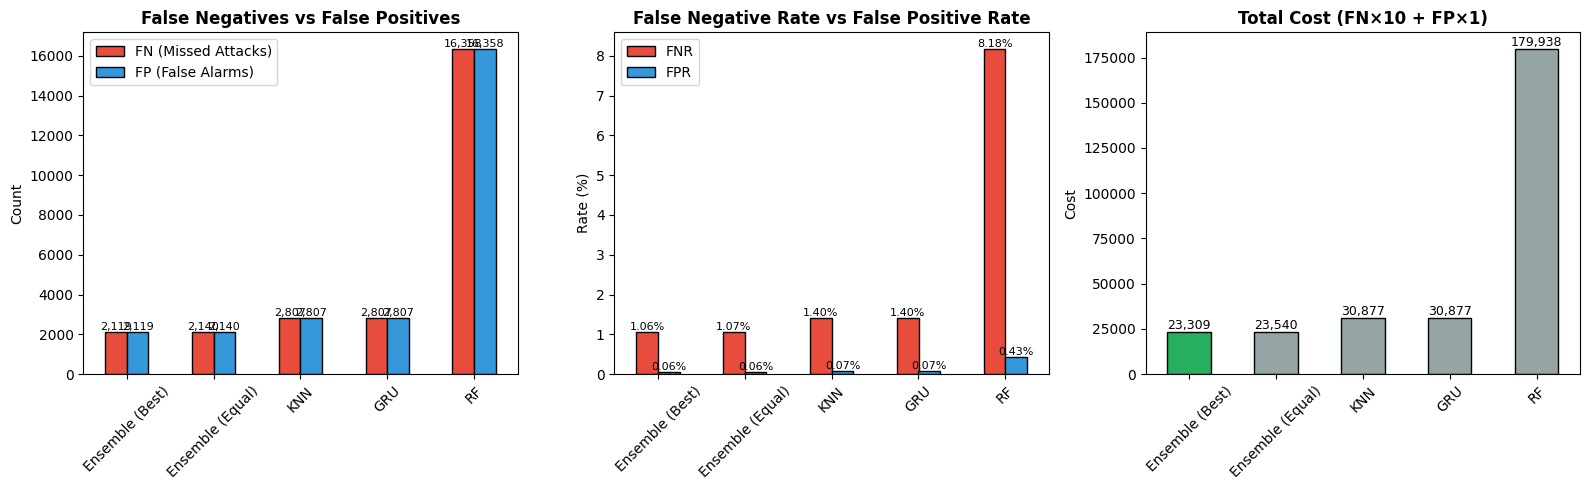


📋 TABLE 2: Per-Class False Positive Rate (FPR)
--------------------------------------------------------------------------------


Model,Ensemble (Best),Ensemble (Equal),GRU,KNN,RF
Class,,,,,
analysis,0.0001,0.0001,0.0000,0.0000,0.0002
backdoor,0.0000,0.0000,0.0000,0.0000,0.0000
benign,0.0032,0.0037,0.0056,0.0060,0.0003
bot,0.0000,0.0000,0.0000,0.0000,0.0000
brute force,0.0000,0.0000,0.0000,0.0000,0.0014
ddos,0.0010,0.0013,0.0019,0.0025,0.0003
dos,0.0016,0.0016,0.0021,0.0009,0.0026
exploits,0.0001,0.0001,0.0001,0.0001,0.0001
fuzzers,0.0002,0.0002,0.0005,0.0002,0.0001



📋 TABLE 3: Per-Class False Negative Rate (FNR)
--------------------------------------------------------------------------------


Model,Ensemble (Best),Ensemble (Equal),GRU,KNN,RF
Class,,,,,
analysis,0.7500,0.7500,1.0000,1.0000,0.1250
backdoor,0.1429,0.1429,0.1746,0.1429,0.1111
benign,0.0052,0.0049,0.0052,0.0077,0.1692
bot,0.0000,0.0000,0.0000,0.0042,0.0000
brute force,0.0362,0.0362,0.0386,0.0386,0.0145
ddos,0.0053,0.0049,0.0050,0.0027,0.0148
dos,0.0295,0.0285,0.0525,0.0468,0.0251
exploits,0.1905,0.2190,0.2857,0.4952,0.1905
fuzzers,0.1200,0.1467,0.0800,0.3200,0.1467


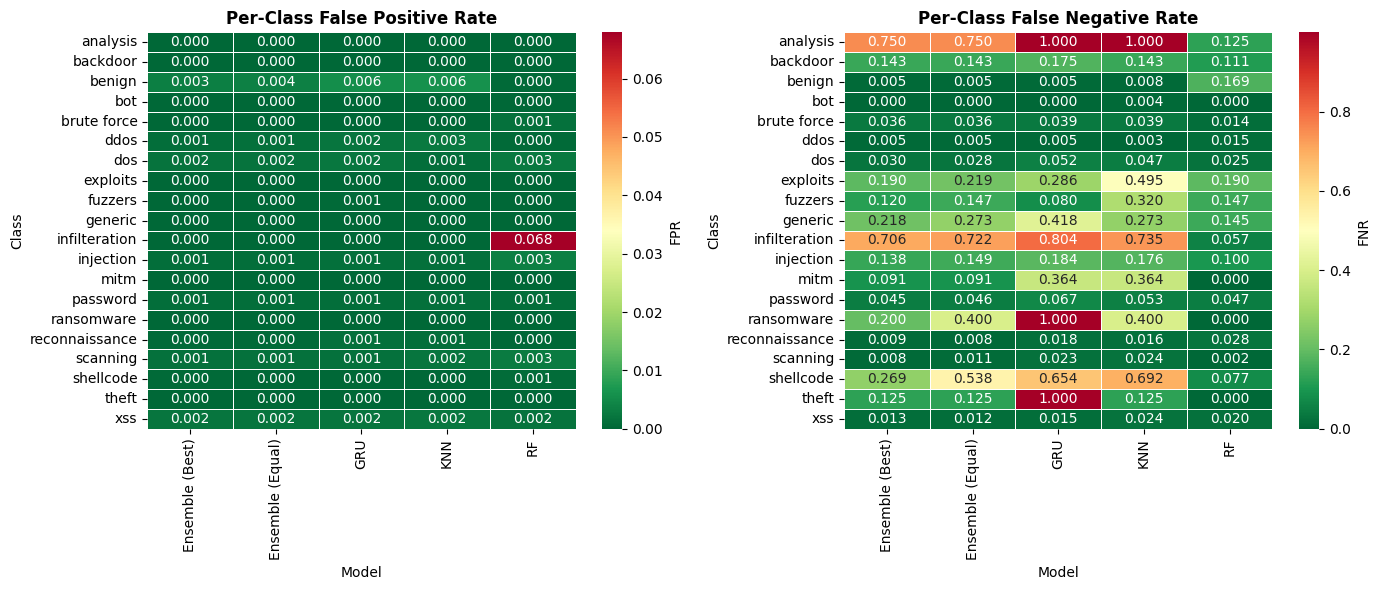


📌 SUMMARY
✅ Lowest Cost Model: Ensemble (Best)
✅ Lowest FNR Model: Ensemble (Best) (fewer missed attacks)
✅ Lowest FPR Model: Ensemble (Best) (fewer false alarms)


In [45]:
# =====================================================
# FN/FP TRADE-OFF ANALYSIS WITH VISUALIZATION
# =====================================================
FN_COST = 10.0
FP_COST = 1.0

from sklearn.metrics import confusion_matrix
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("="*80)
print("📊 FALSE NEGATIVE / FALSE POSITIVE TRADE-OFF ANALYSIS")
print("="*80)

# Ensure eval_idx and y_eval exist
if "eval_idx" not in globals() or "y_eval" not in globals():
    from sklearn.model_selection import StratifiedShuffleSplit
    EVAL_SIZE = 200_000
    RANDOM_STATE = 42
    sss = StratifiedShuffleSplit(n_splits=1, test_size=EVAL_SIZE, random_state=RANDOM_STATE)
    for _, eval_idx in sss.split(X_tab_val, y_val):
        X_eval = X_tab_val[eval_idx]
        y_eval = y_val.iloc[eval_idx] if hasattr(y_val, "iloc") else y_val[eval_idx]
    print(f"✅ Created shared eval set: {len(y_eval)} samples")

label_list = sorted(np.unique(y_eval))
label_names = class_names if 'class_names' in globals() else [str(l) for l in label_list]

def confusion_stats(y_true, preds, labels):
    cm = confusion_matrix(y_true, preds, labels=labels)
    tp = np.diag(cm)
    fn = cm.sum(axis=1) - tp
    fp = cm.sum(axis=0) - tp
    tn = cm.sum() - tp - fn - fp
    fpr = fp / (fp + tn + 1e-9)
    fnr = fn / (fn + tp + 1e-9)
    return tp, fp, fn, tn, fpr, fnr

# Predictions ON SHARED EVAL SET
gru_eval_probs = gru_val_probs[eval_idx]
rf_eval_probs = rf_val_probs[eval_idx]
knn_eval_probs = knn.predict_proba(X_eval)

gru_eval_preds = np.argmax(gru_eval_probs, axis=1)
rf_eval_preds = np.argmax(rf_eval_probs, axis=1)
knn_eval_preds = np.argmax(knn_eval_probs, axis=1)

ensemble_eval_probs = (gru_eval_probs + rf_eval_probs + knn_eval_probs) / 3.0
ensemble_eval_preds = np.argmax(ensemble_eval_probs, axis=1)

model_preds = {
    "GRU": gru_eval_preds,
    "RF": rf_eval_preds,
    "KNN": knn_eval_preds,
    "Ensemble (Equal)": ensemble_eval_preds,
}

if "best_row" in globals():
    w_gru, w_knn, w_rf = best_row.w_gru, best_row.w_knn, best_row.w_rf
    best_eval_probs = w_gru * gru_eval_probs + w_knn * knn_eval_probs + w_rf * rf_eval_probs
    best_eval_preds = np.argmax(best_eval_probs, axis=1)
    model_preds["Ensemble (Best)"] = best_eval_preds

# Compute stats for all models
cost_rows = []
per_class_rows = []

for model_name, preds in model_preds.items():
    tp, fp, fn, tn, fpr, fnr = confusion_stats(y_eval, preds, label_list)
    
    total_fn = fn.sum()
    total_fp = fp.sum()
    total_tp = tp.sum()
    total_tn = tn.sum()
    cost = FN_COST * total_fn + FP_COST * total_fp
    
    overall_fpr = total_fp / (total_fp + total_tn + 1e-9)
    overall_fnr = total_fn / (total_fn + total_tp + 1e-9)
    
    cost_rows.append({
        "Model": model_name,
        "Total TP": int(total_tp),
        "Total FP": int(total_fp),
        "Total FN": int(total_fn),
        "Total TN": int(total_tn),
        "FPR (%)": overall_fpr * 100,
        "FNR (%)": overall_fnr * 100,
        "Cost (FN×10 + FP)": float(cost),
    })
    
    for i, cls in enumerate(label_list):
        per_class_rows.append({
            "Model": model_name,
            "Class": label_names[i],
            "FPR": fpr[i],
            "FNR": fnr[i],
            "TP": tp[i],
            "FP": fp[i],
            "FN": fn[i],
        })

cost_df = pd.DataFrame(cost_rows).sort_values("Cost (FN×10 + FP)")
per_class_df = pd.DataFrame(per_class_rows)

# -----------------------------------------------------
# TABLE 1: Overall Cost Analysis
# -----------------------------------------------------
print("\n📋 TABLE 1: Overall FN/FP Cost Analysis")
print(f"   Cost Formula: {FN_COST}×FN + {FP_COST}×FP (lower is better)")
print("-"*80)
display(
    cost_df.set_index("Model")
    .style.format({
        "Total TP": "{:,.0f}",
        "Total FP": "{:,.0f}",
        "Total FN": "{:,.0f}",
        "Total TN": "{:,.0f}",
        "FPR (%)": "{:.2f}%",
        "FNR (%)": "{:.2f}%",
        "Cost (FN×10 + FP)": "{:,.0f}",
    })
    .background_gradient(cmap="RdYlGn_r", subset=["Cost (FN×10 + FP)", "FPR (%)", "FNR (%)"])
    .background_gradient(cmap="RdYlGn", subset=["Total TP"])
)

# -----------------------------------------------------
# FIGURE 1: FN vs FP Bar Chart
# -----------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Plot 1: FN/FP counts
plot_df = cost_df.set_index("Model")[["Total FN", "Total FP"]]
plot_df.plot(kind="bar", ax=axes[0], color=["#e74c3c", "#3498db"], edgecolor="black")
axes[0].set_title("False Negatives vs False Positives", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Count")
axes[0].set_xlabel("")
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(["FN (Missed Attacks)", "FP (False Alarms)"])
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='{:,.0f}', fontsize=8)

# Plot 2: FPR/FNR rates
rate_df = cost_df.set_index("Model")[["FNR (%)", "FPR (%)"]]
rate_df.plot(kind="bar", ax=axes[1], color=["#e74c3c", "#3498db"], edgecolor="black")
axes[1].set_title("False Negative Rate vs False Positive Rate", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Rate (%)")
axes[1].set_xlabel("")
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(["FNR", "FPR"])
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='{:.2f}%', fontsize=8)

# Plot 3: Total Cost
cost_plot = cost_df.set_index("Model")["Cost (FN×10 + FP)"]
colors = ["#27ae60" if m == cost_plot.idxmin() else "#95a5a6" for m in cost_plot.index]
cost_plot.plot(kind="bar", ax=axes[2], color=colors, edgecolor="black")
axes[2].set_title(f"Total Cost (FN×{int(FN_COST)} + FP×{int(FP_COST)})", fontsize=12, fontweight="bold")
axes[2].set_ylabel("Cost")
axes[2].set_xlabel("")
axes[2].tick_params(axis='x', rotation=45)
for container in axes[2].containers:
    axes[2].bar_label(container, fmt='{:,.0f}', fontsize=9)

plt.tight_layout()
plt.show()

# -----------------------------------------------------
# TABLE 2: Per-Class FPR Heatmap
# -----------------------------------------------------
print("\n📋 TABLE 2: Per-Class False Positive Rate (FPR)")
print("-"*80)
fpr_pivot = per_class_df.pivot_table(index="Class", columns="Model", values="FPR")
display(
    fpr_pivot.round(4)
    .style.format("{:.4f}")
    .background_gradient(cmap="RdYlGn_r", axis=1)
)

# -----------------------------------------------------
# TABLE 3: Per-Class FNR Heatmap
# -----------------------------------------------------
print("\n📋 TABLE 3: Per-Class False Negative Rate (FNR)")
print("-"*80)
fnr_pivot = per_class_df.pivot_table(index="Class", columns="Model", values="FNR")
display(
    fnr_pivot.round(4)
    .style.format("{:.4f}")
    .background_gradient(cmap="RdYlGn_r", axis=1)
)

# -----------------------------------------------------
# FIGURE 2: Per-Class FNR Heatmap Visualization
# -----------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(fpr_pivot, annot=True, fmt=".3f", cmap="RdYlGn_r", ax=axes[0], 
            linewidths=0.5, cbar_kws={"label": "FPR"})
axes[0].set_title("Per-Class False Positive Rate", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("Class")

sns.heatmap(fnr_pivot, annot=True, fmt=".3f", cmap="RdYlGn_r", ax=axes[1],
            linewidths=0.5, cbar_kws={"label": "FNR"})
axes[1].set_title("Per-Class False Negative Rate", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("Class")

plt.tight_layout()
plt.show()

# Summary
print("\n" + "="*80)
print("📌 SUMMARY")
print("="*80)
best_cost_model = cost_df.iloc[0]["Model"]
best_fnr_model = cost_df.loc[cost_df["FNR (%)"].idxmin(), "Model"]
best_fpr_model = cost_df.loc[cost_df["FPR (%)"].idxmin(), "Model"]
print(f"✅ Lowest Cost Model: {best_cost_model}")
print(f"✅ Lowest FNR Model: {best_fnr_model} (fewer missed attacks)")
print(f"✅ Lowest FPR Model: {best_fpr_model} (fewer false alarms)")